In [15]:
%run ./functions.ipynb
random.seed(42)

In [6]:
z_by_d = {}
log_z_by_d = {}

for d in [2, 4, 6, 8, 10]:
    y_vec = np.zeros(d)
    y_vec[0] = 0.5
    log_Z, Z = compute_log_Z_even(y_vec, [0.1, 0.01])
    z_by_d[d] = Z
    log_z_by_d[d] = log_Z
    print(f"d = {d} -> log Z = {log_Z:.6f}, Z = {Z:.6f}")

d = 2 -> log Z = -1.144730, Z = 0.318310
d = 4 -> log Z = -1.596313, Z = 0.202642
d = 6 -> log Z = -1.642430, Z = 0.193509
d = 8 -> log Z = -1.400866, Z = 0.246383
d = 10 -> log Z = -0.936158, Z = 0.392131


# $\alpha=e^{-1}$

## ANS-SMC

In [37]:
class Options:
    pass

dims = [2, 4, 6, 8, 10]
N = 10000
alpha = np.exp(-1)
repeats = 10
num_repeats = 1

def run_ans_smc_for_d(
    d_val,
    levels_store,
    meta_store,
    alpha = np.exp(-1), 
    num_repeats=1,
    plot_diagnostics=True,
):
    d_int = int(d_val)
    print(f"d={d_int}")
    ref_log_z = float(log_z_by_d[d_int])
    ref_z = float(z_by_d[d_int])

    rows = []
    for i in range(num_repeats):
        options = Options()
        options.N = N
        options.d = d_int
        options.alpha = alpha
        options.R = repeats
        options.sig = 0.1

        np.random.seed(i)
        t_start = time.time()
        (
            log_evidence,
            count_loglike,
            levels,
            log_unnormalized_w,
            log_normalized_w,
            log_evidence_t,
            prop_1sd,
            prop_2sd,
            prop_3sd,
            accept_rate_t,
            accept_spike_t,
            accept_slab_t,
            total_prop_spike,
            total_prop_slab,
        ) = ANS_SMC_bespoke_RW(
            loglike_fn, logprior_fn, simprior_fn, options, False
        )
        t_elapsed = time.time() - t_start

        # Save the threshold schedule and runtime metadata for this (d, repeat)
        levels_store[(d_int, i)] = np.asarray(levels).copy()
        meta_store[(d_int, i)] = {
            "count_loglike": count_loglike,
            "elapsed_sec": t_elapsed,
        }

        if plot_diagnostics:
            plot_ans_smc_diagnostics(
                levels=levels,
                log_evidence_t=log_evidence_t,
                prop_1sd=prop_1sd,
                prop_2sd=prop_2sd,
                prop_3sd=prop_3sd,
                accept_rate_t=accept_rate_t,
                accept_spike_t=accept_spike_t,
                accept_slab_t=accept_slab_t,
                true_log_z=ref_log_z,
                label_prefix=f"ANS-SMC (d={d_int}, N={N}, rep={i})",
            )

        rows.append({
            "d": d_int,
            "repeat": i,
            "log_evidence": log_evidence,
            "ref_log_z": ref_log_z,
            "log_err": log_evidence - ref_log_z,
            "Z": np.exp(log_evidence),
            "ref_Z": ref_z,
            "count_loglike": count_loglike,
            "elapsed_sec": t_elapsed,
            "total_prop_spike": total_prop_spike,
            "total_prop_slab": total_prop_slab,
        })
    return pd.DataFrame(rows)


def run_all_ans_smc(dims_list, alpha=np.exp(-1), num_repeats=1, plot_diagnostics=True):
    levels_ans_smc = {}
    ans_meta_by_run = {}

    df_ans_smc = pd.concat(
        [
            run_ans_smc_for_d(
                d_val,
                levels_store=levels_ans_smc,
                meta_store=ans_meta_by_run,
                alpha = alpha, 
                num_repeats=num_repeats,
                plot_diagnostics=plot_diagnostics,
            )
            for d_val in dims_list
        ],
        ignore_index=True,
    )

    return df_ans_smc, levels_ans_smc, ans_meta_by_run

d=2


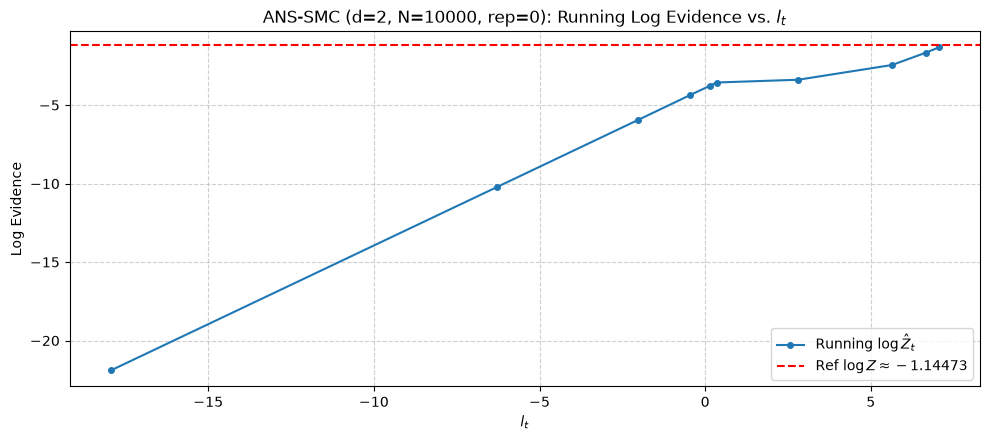

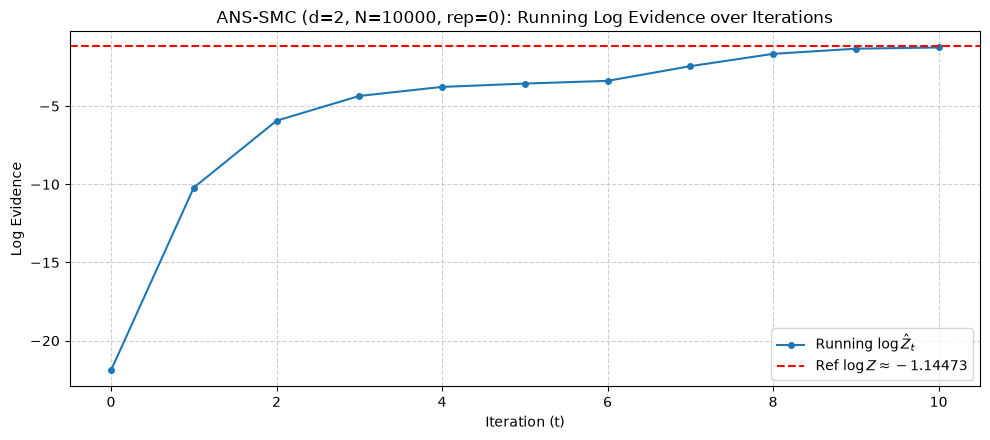

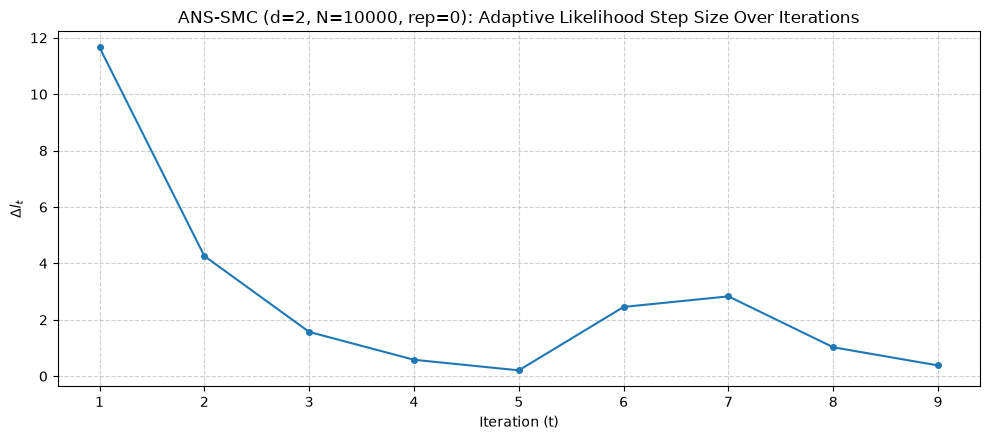

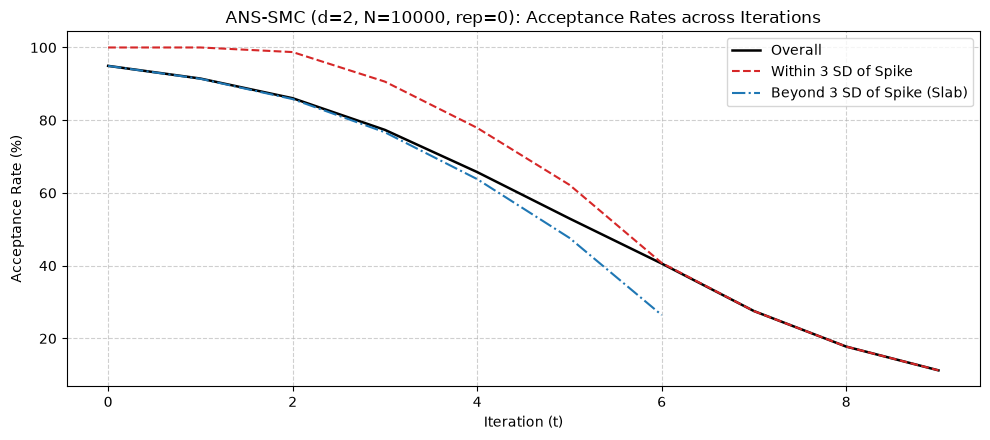

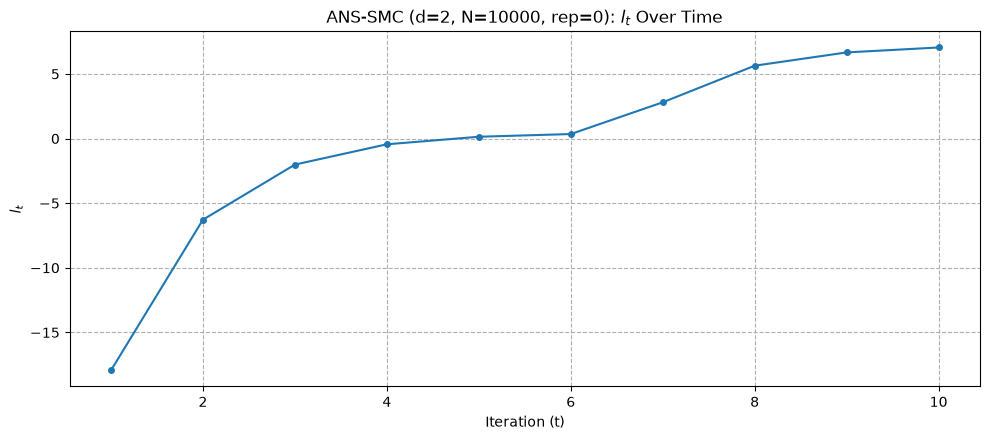

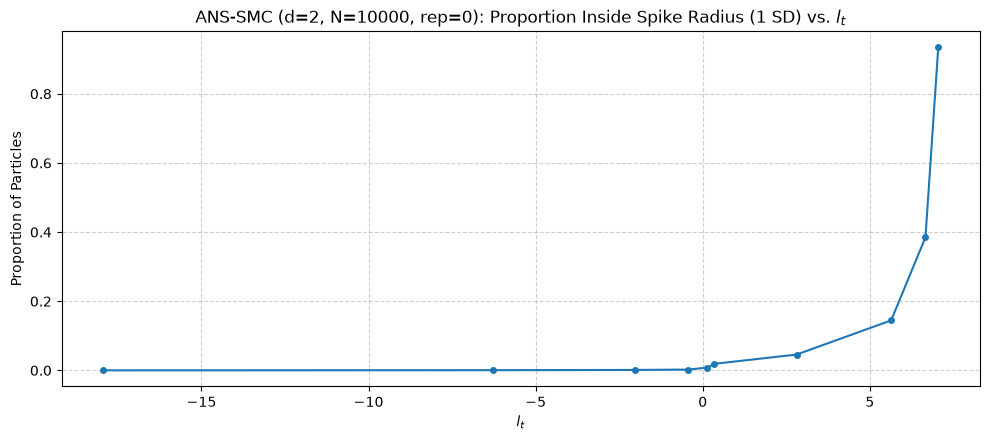

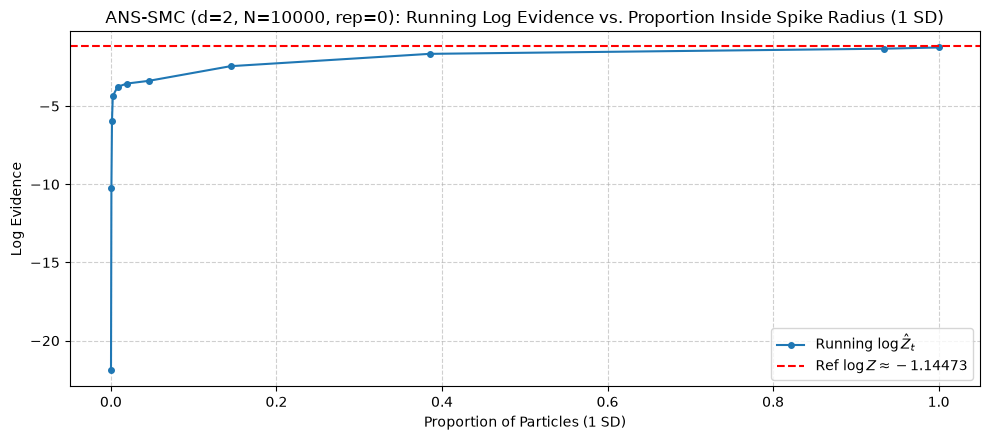

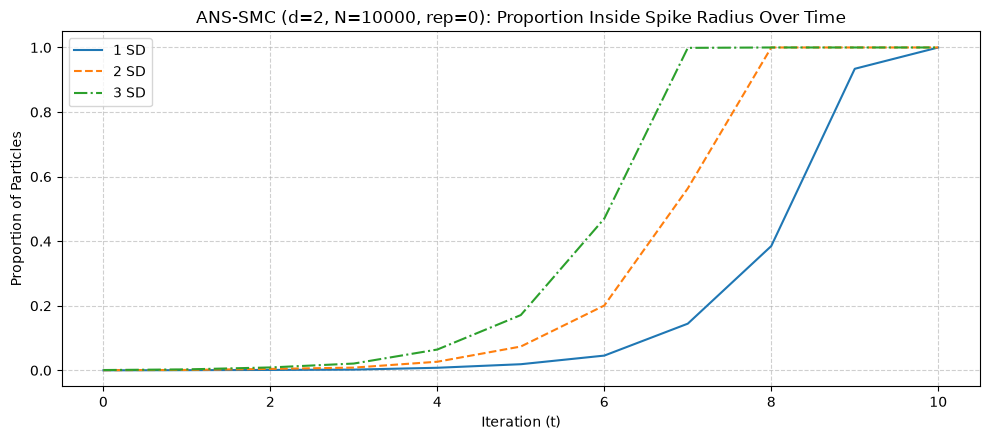

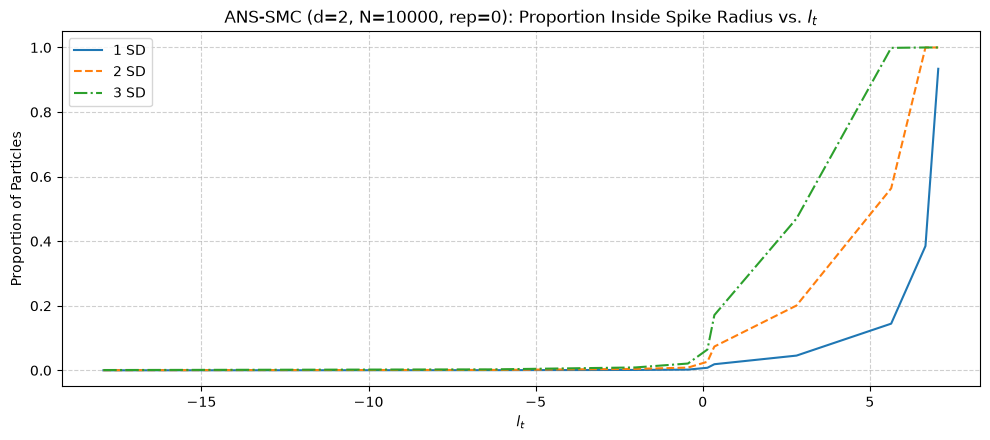

d=4


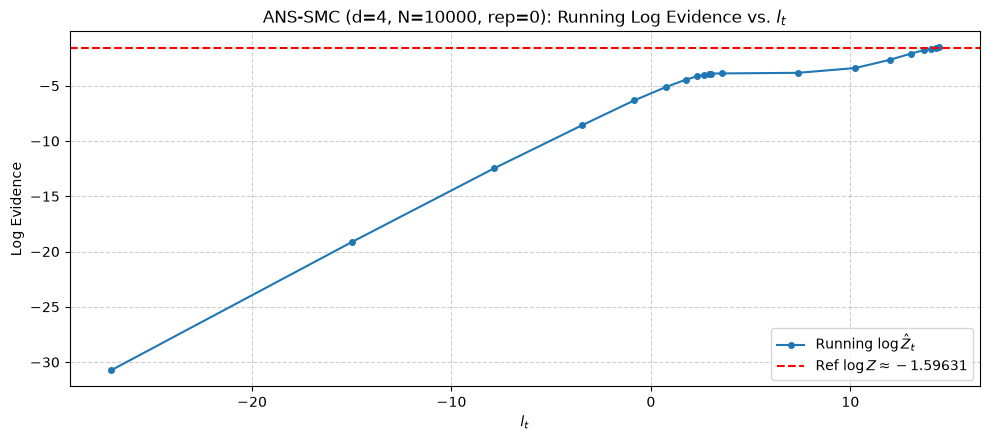

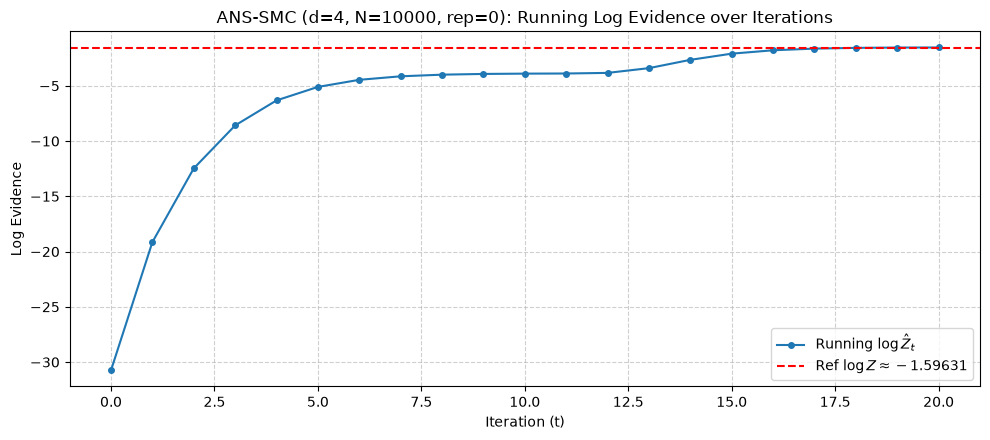

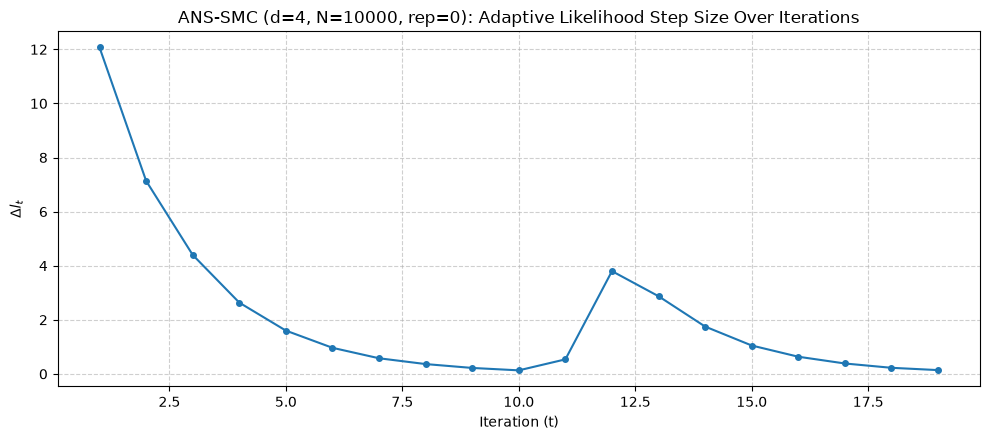

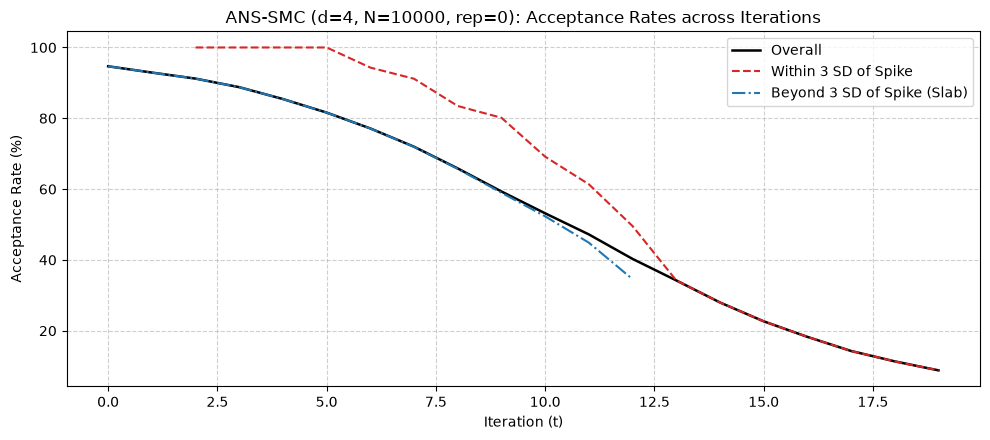

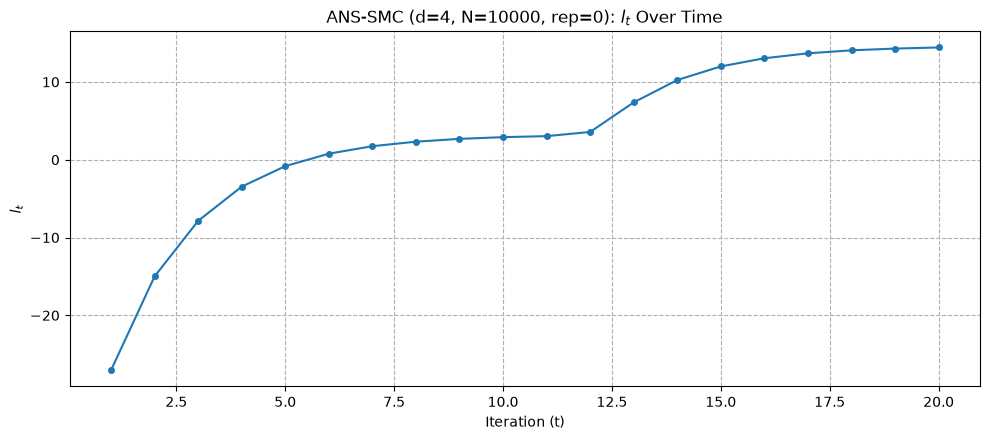

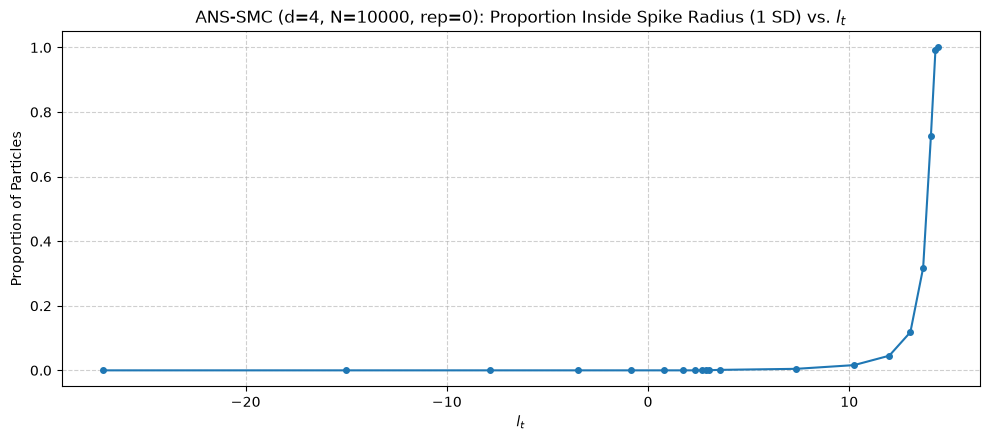

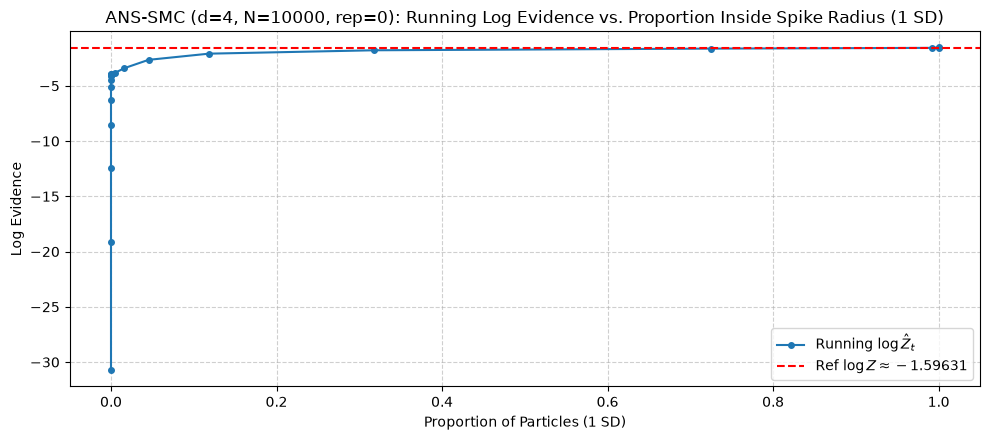

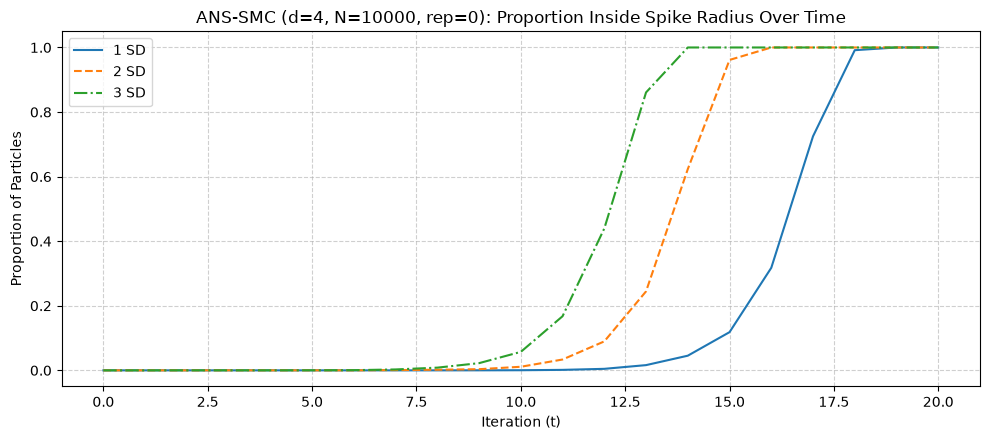

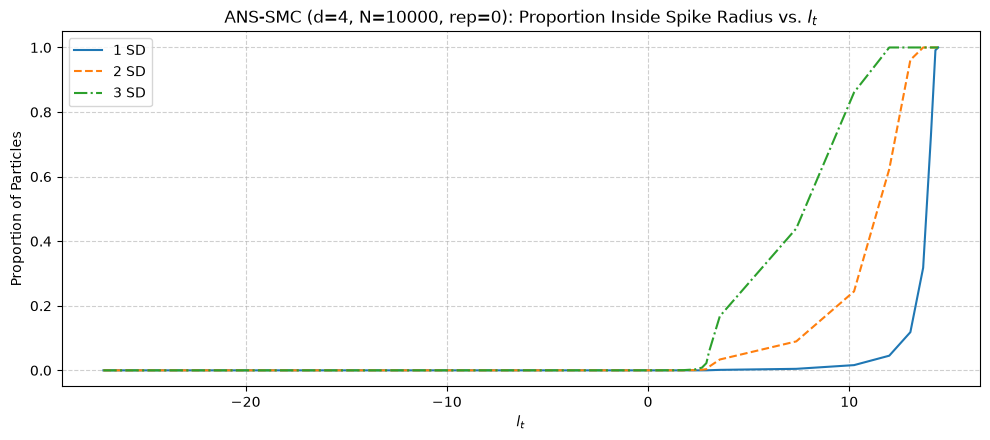

d=6


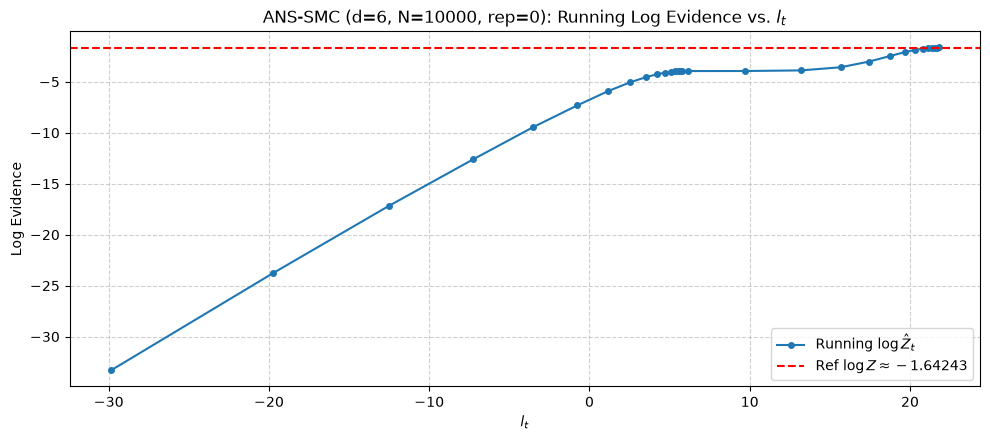

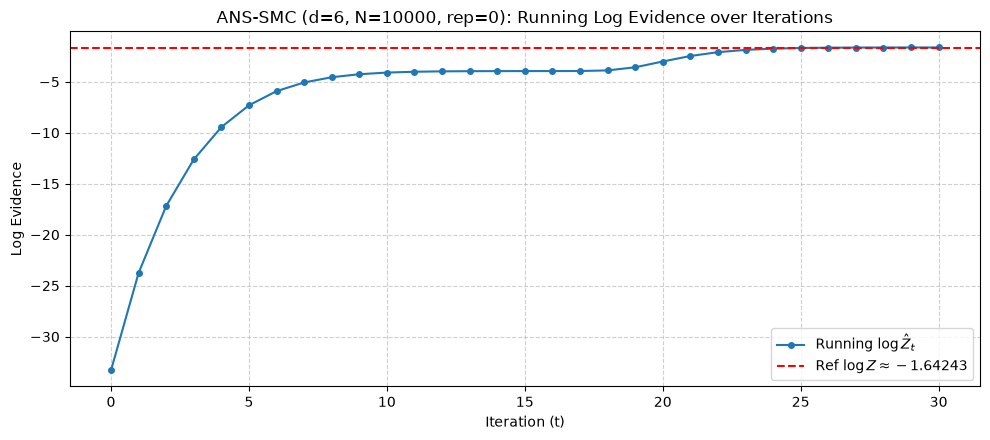

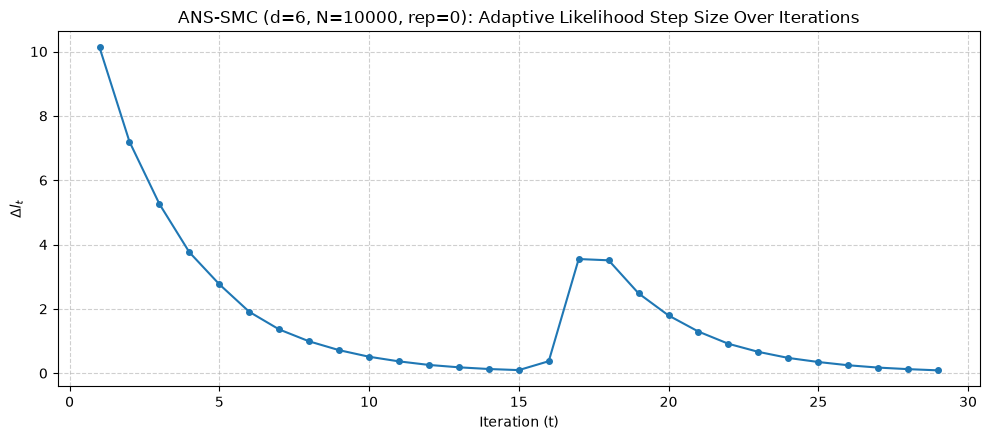

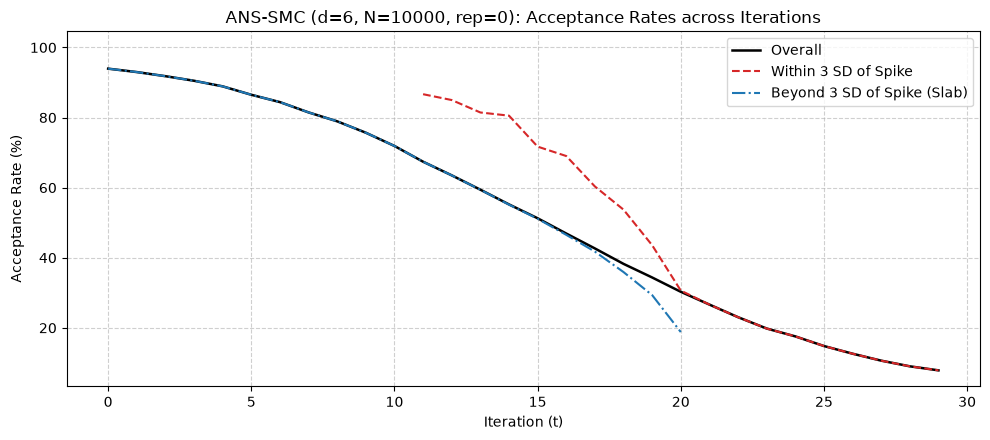

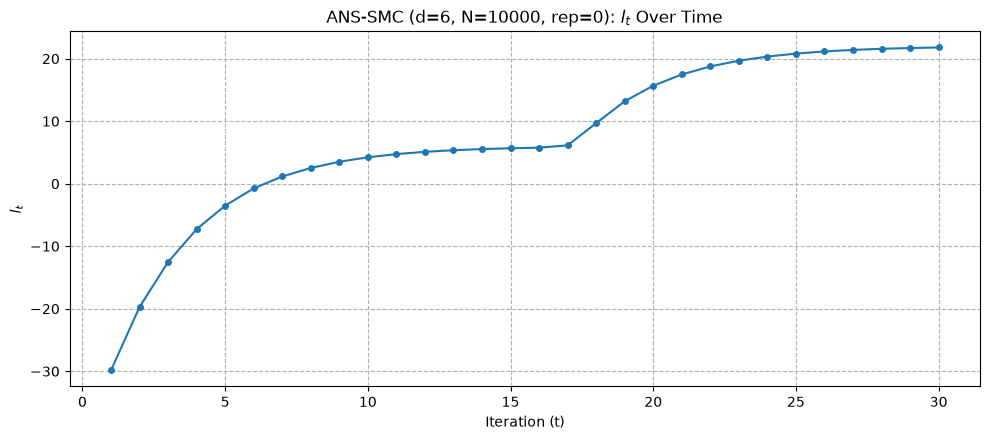

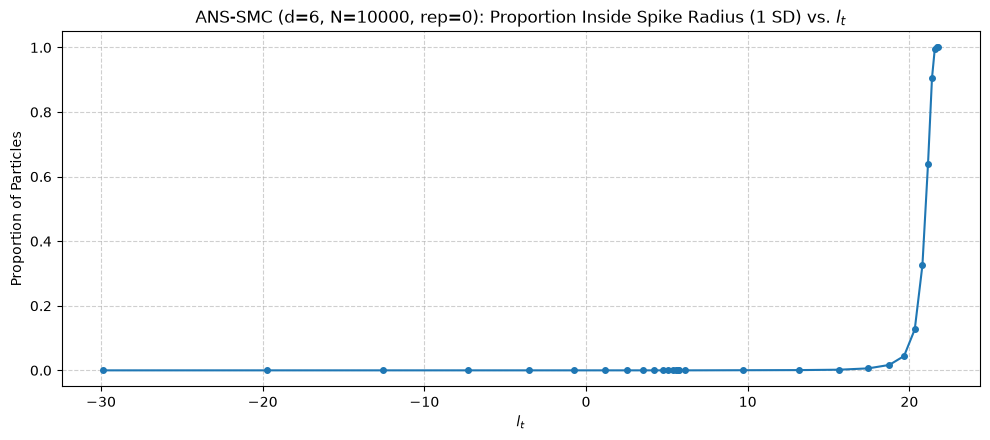

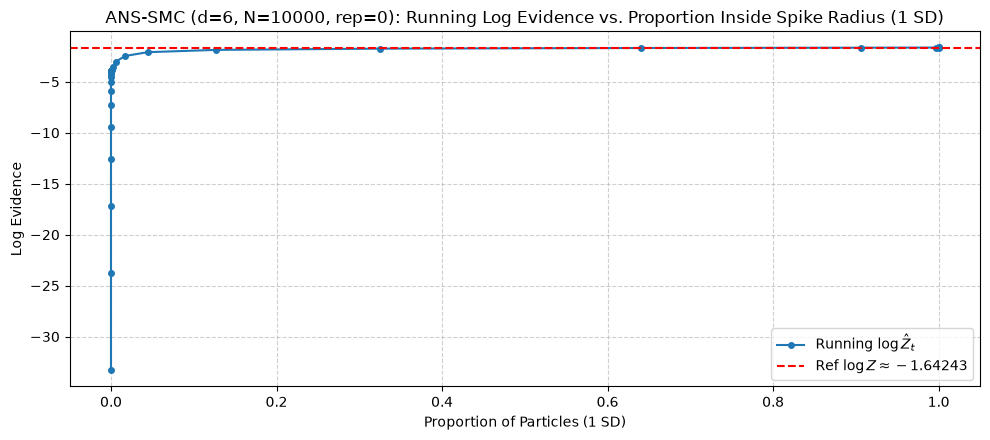

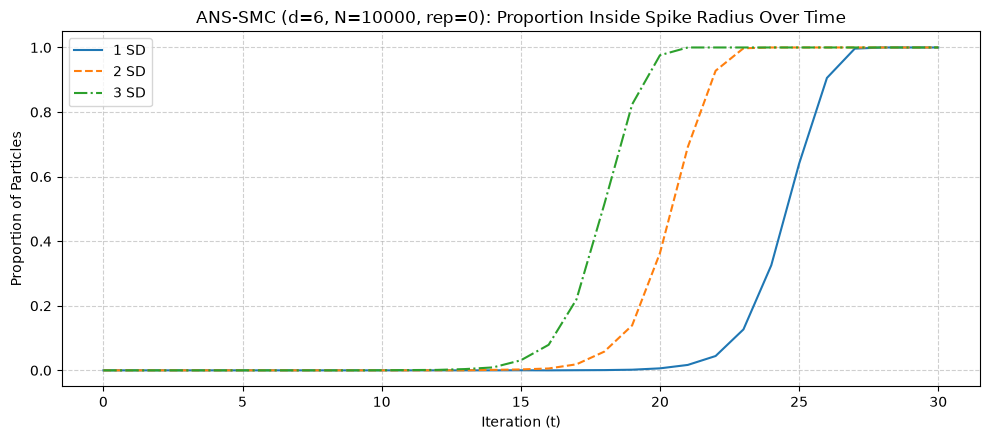

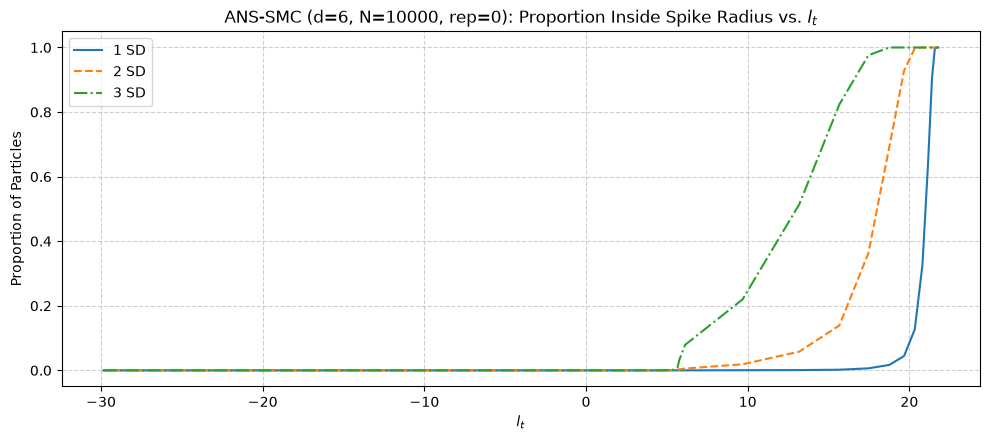

d=8


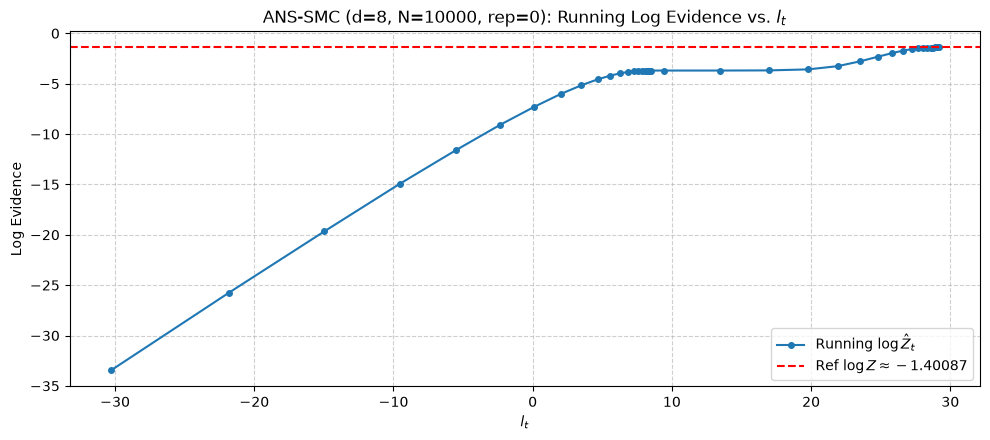

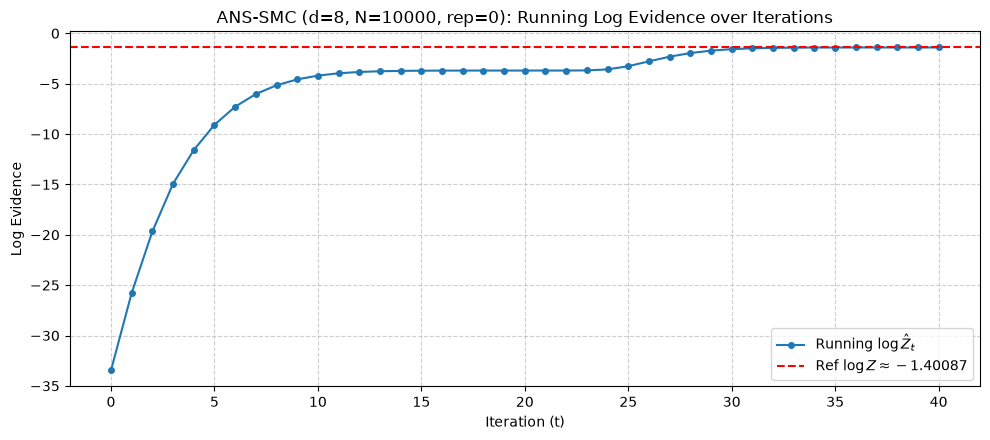

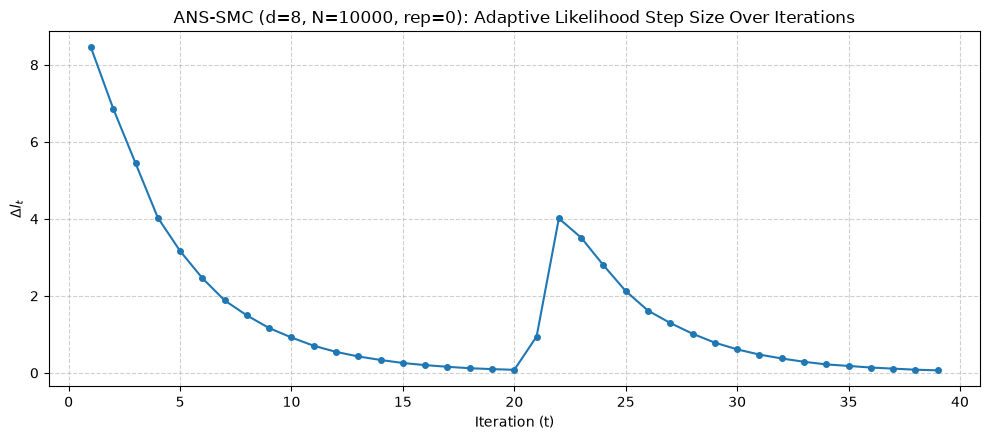

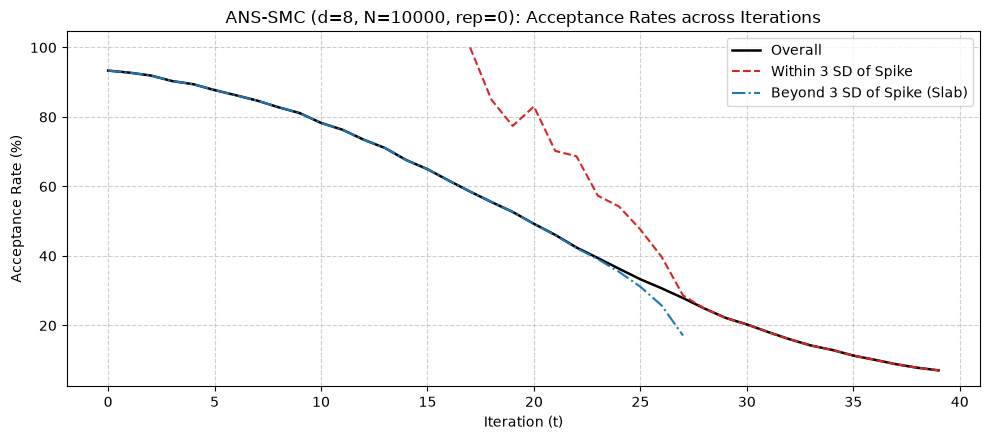

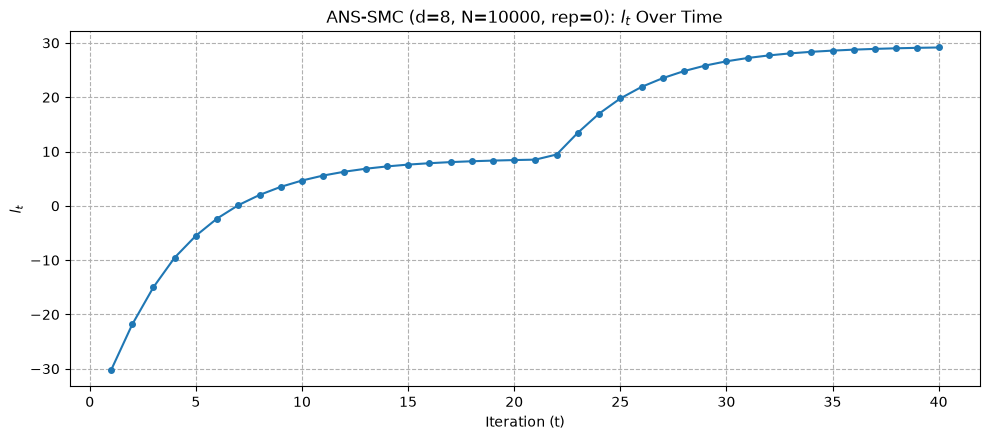

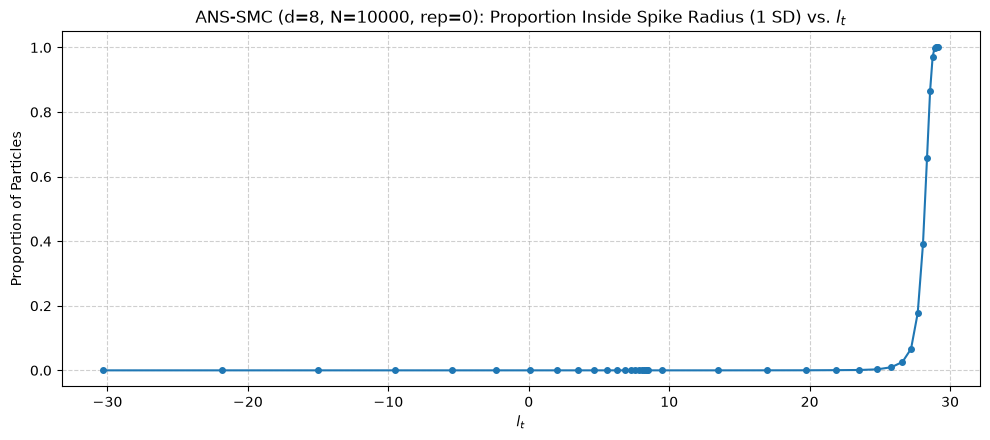

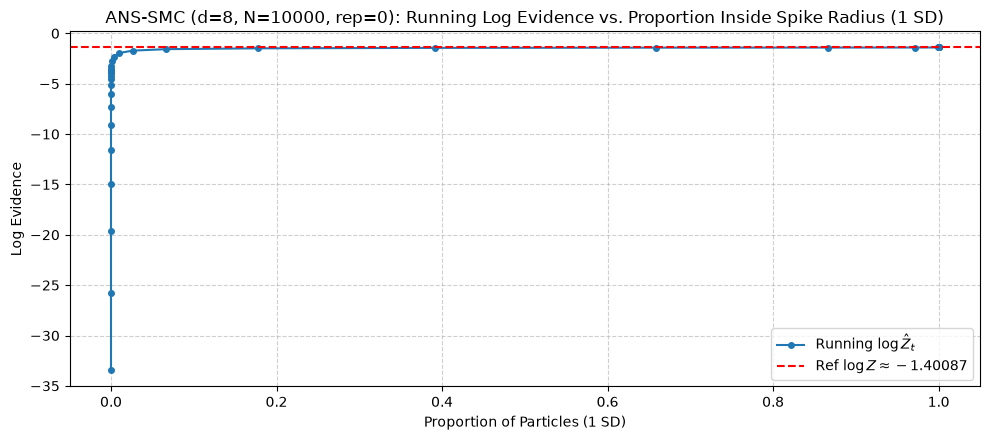

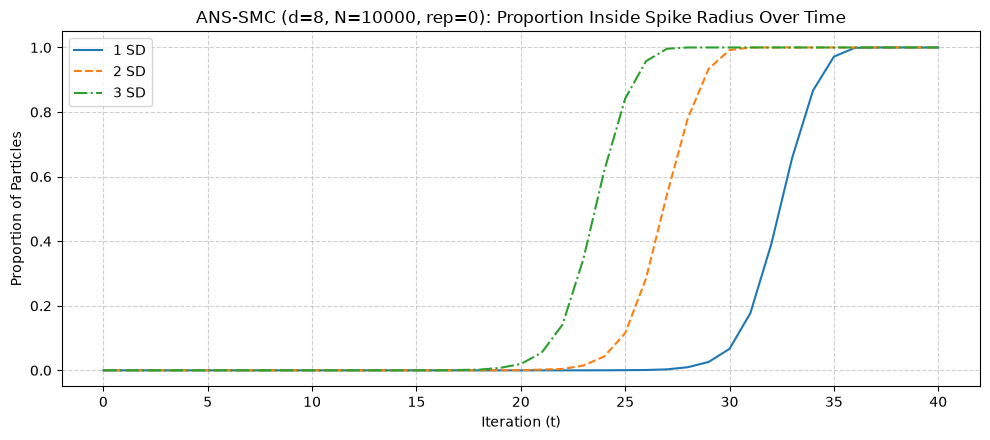

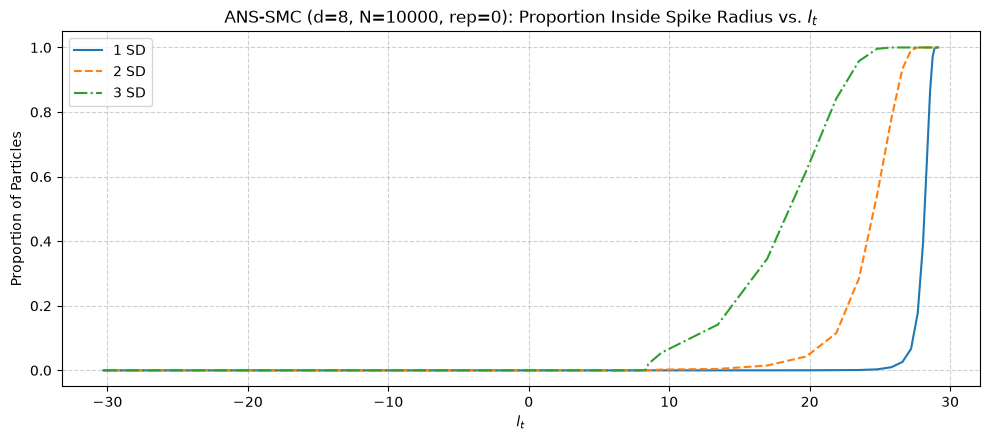

d=10


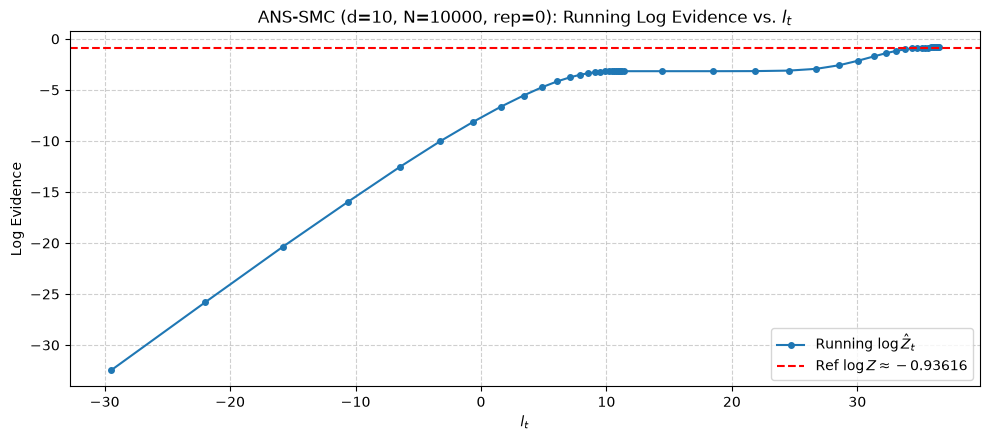

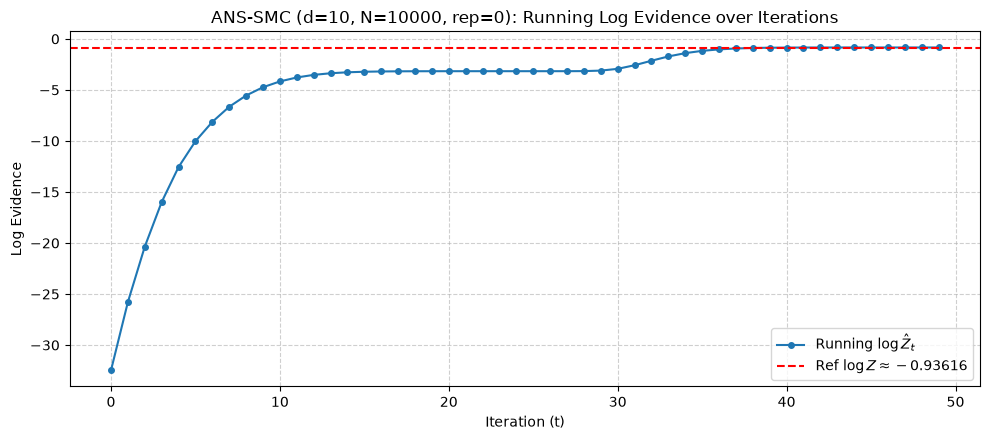

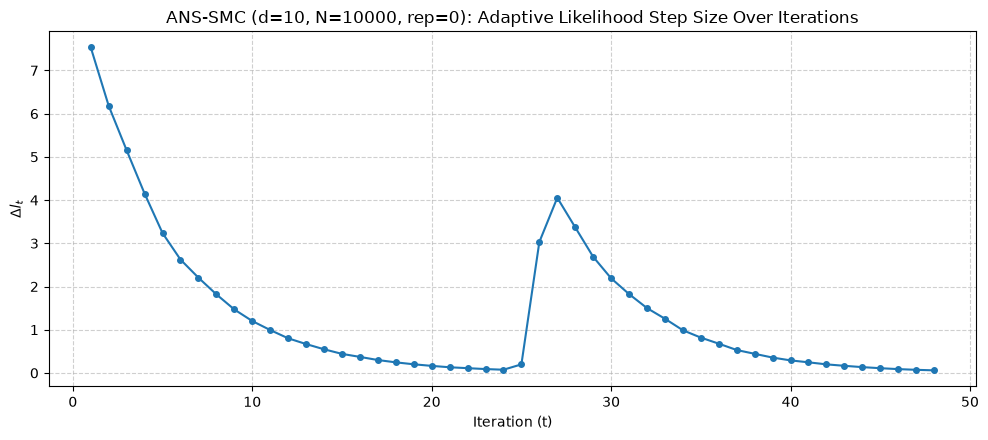

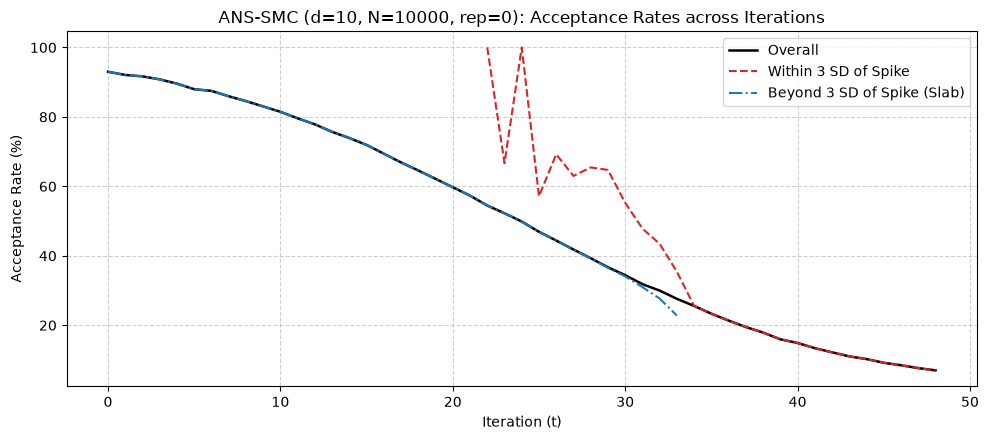

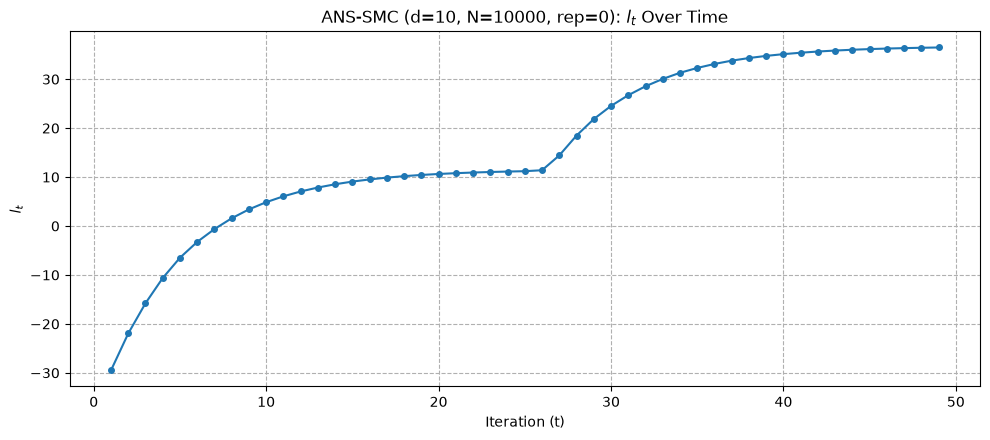

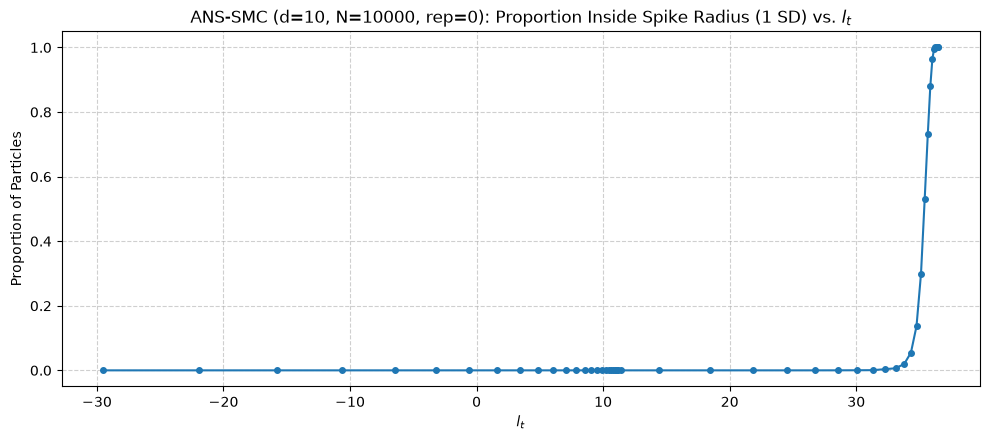

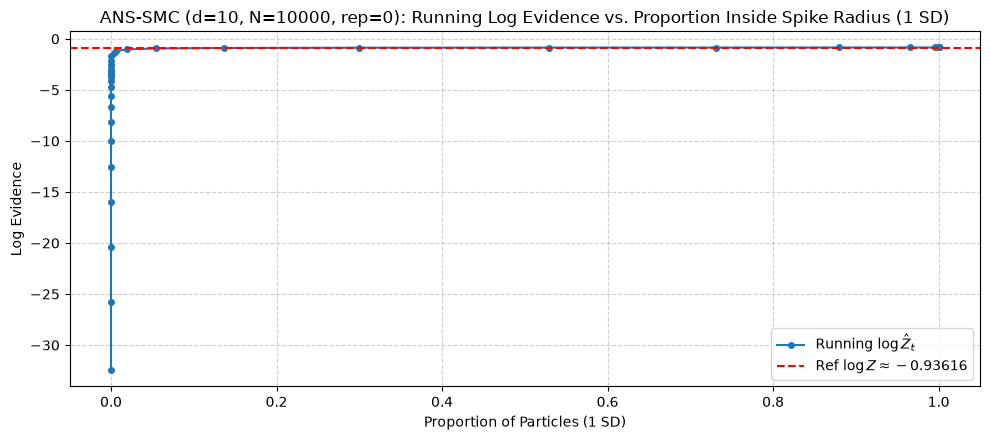

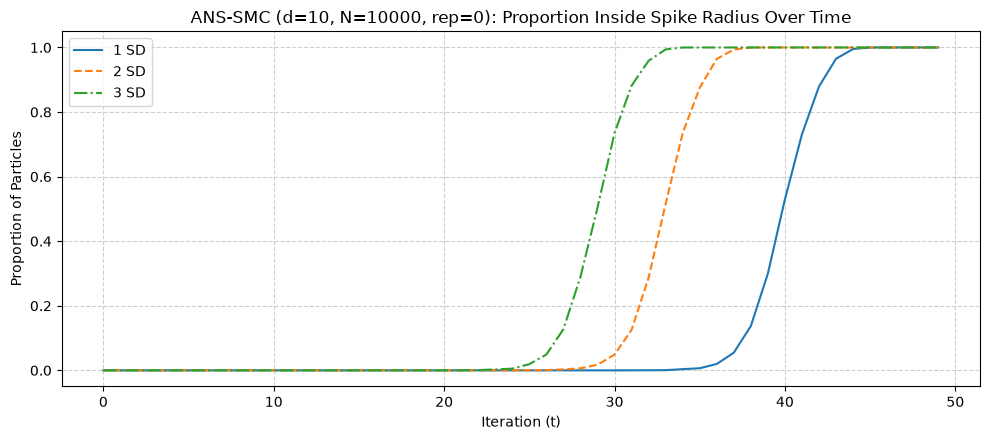

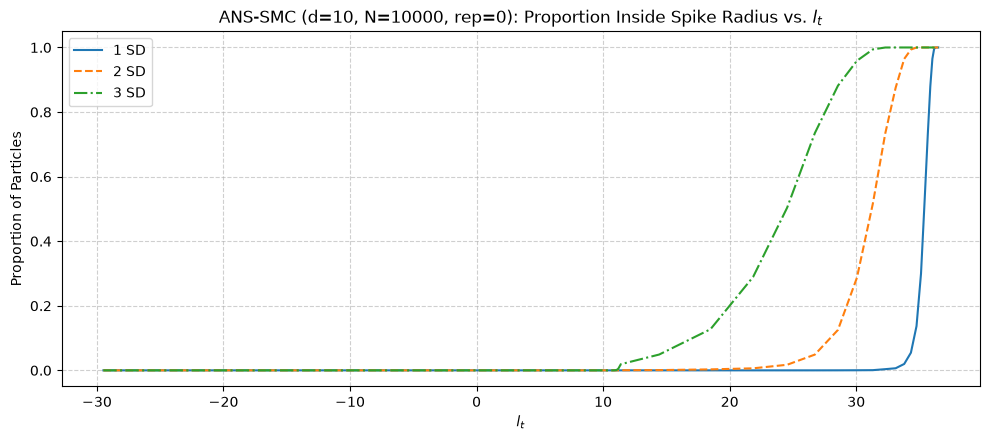

In [38]:
df_ans_smc, levels_ans_smc, ans_meta_by_run = run_all_ans_smc(
    dims, alpha=alpha, num_repeats=num_repeats, plot_diagnostics=True
)

In [39]:
df_ans_smc["true_Z"] = df_ans_smc["d"].map(z_by_d)
df_ans_smc["true_log_Z"] = df_ans_smc["d"].map(log_z_by_d)
df_ans_smc["abs_error"] = np.sqrt((df_ans_smc["Z"] - df_ans_smc["true_Z"]) ** 2)
df_ans_smc[["d", "log_evidence", "true_log_Z", "Z", "true_Z", "abs_error", "total_prop_spike", "total_prop_slab"]]

,d,log_evidence,true_log_Z,Z,true_Z,abs_error,total_prop_spike,total_prop_slab
0,2,-1.250285,-1.144730,0.286423,0.318310,0.031887,100000,0
1,4,-1.529810,-1.596313,0.216577,0.202642,0.013934,100000,0
2,6,-1.632843,-1.642430,0.195373,0.193509,0.001864,100000,0
3,8,-1.405125,-1.400866,0.245336,0.246383,0.001047,100000,0
4,10,-0.842629,-0.936158,0.430577,0.392131,0.038446,100000,0


## NS-SMC

In [40]:
def run_ns_smc_for_d(d_val, levels_ans_smc, ans_meta_by_run, num_repeats=1, add_ans_costs=True, plot_diagnostics=True):
    d_int = int(d_val)
    ref_log_z = float(log_z_by_d[d_int])
    ref_z = float(z_by_d[d_int])

    rows = []
    for i in range(num_repeats):
        if (d_int, i) not in levels_ans_smc:
            raise KeyError(f"Missing saved ANS-SMC levels for (d={d_int}, repeat={i}).")

        saved_levels = levels_ans_smc[(d_int, i)]

        options = Options()
        options.N = N
        options.d = d_int
        options.levels = saved_levels
        options.R = repeats
        options.sig = 0.1

        np.random.seed(i + num_repeats)
        t_start = time.time()
        (
            log_evidence,
            count_loglike,
            error_flag,
            log_unnormalized_w,
            log_normalized_w,
            log_evidence_t,
            prop_1sd,
            prop_2sd,
            prop_3sd,
            accept_rate_t,
            accept_spike_t,
            accept_slab_t,
            total_prop_spike,
            total_prop_slab,
        ) = NS_SMC_bespoke_RW(
            loglike_fn, logprior_fn, simprior_fn, options, False
        )
        t_elapsed = time.time() - t_start

        if plot_diagnostics:
            plot_ns_smc_diagnostics(
                levels=saved_levels,
                log_evidence_t=log_evidence_t,
                prop_1sd=prop_1sd,
                prop_2sd=prop_2sd,
                prop_3sd=prop_3sd,
                accept_rate_t=accept_rate_t,
                accept_spike_t=accept_spike_t,
                accept_slab_t=accept_slab_t,
                true_log_z=ref_log_z,
                label_prefix=f"NS-SMC (d={d_int}, N={N}, rep={i})",
            )

        ans_count = ans_meta_by_run[(d_int, i)]["count_loglike"] if add_ans_costs else 0.0
        ans_time = ans_meta_by_run[(d_int, i)]["elapsed_sec"] if add_ans_costs else 0.0

        rows.append({
            "d": d_int,
            "repeat": i,
            "log_evidence": log_evidence,
            "ref_log_z": ref_log_z,
            "log_err": log_evidence - ref_log_z,
            "Z": np.exp(log_evidence),
            "ref_Z": ref_z,
            "count_loglike": count_loglike + ans_count,
            "ns_only_count_loglike": count_loglike,
            "elapsed_sec": t_elapsed + ans_time,
            "ns_only_elapsed_sec": t_elapsed,
            "error_flag": error_flag,
            "total_prop_spike": total_prop_spike,
            "total_prop_slab": total_prop_slab,
        })
    return pd.DataFrame(rows)

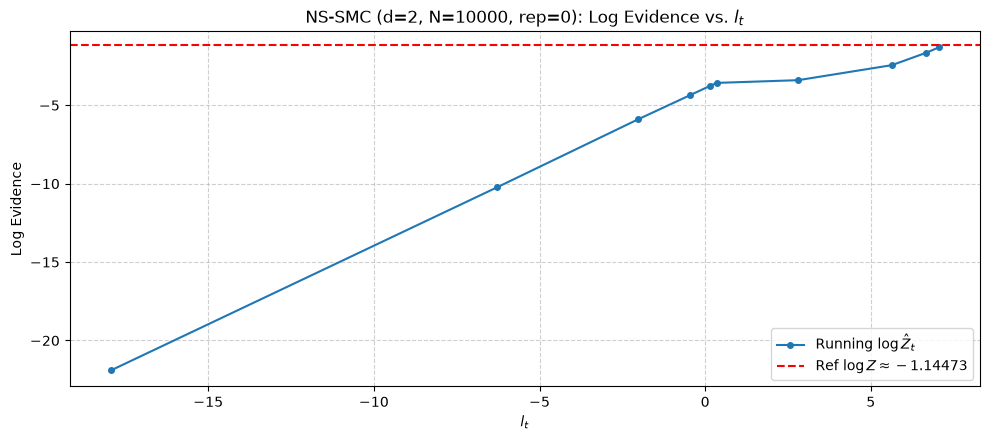

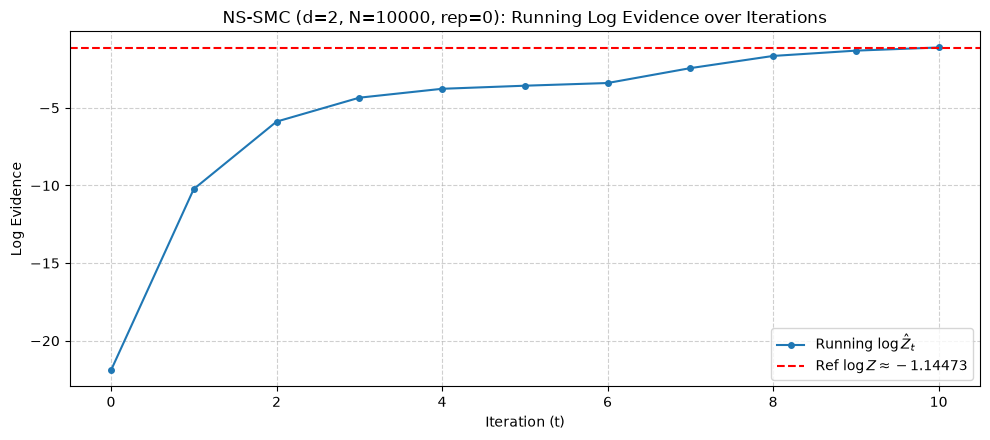

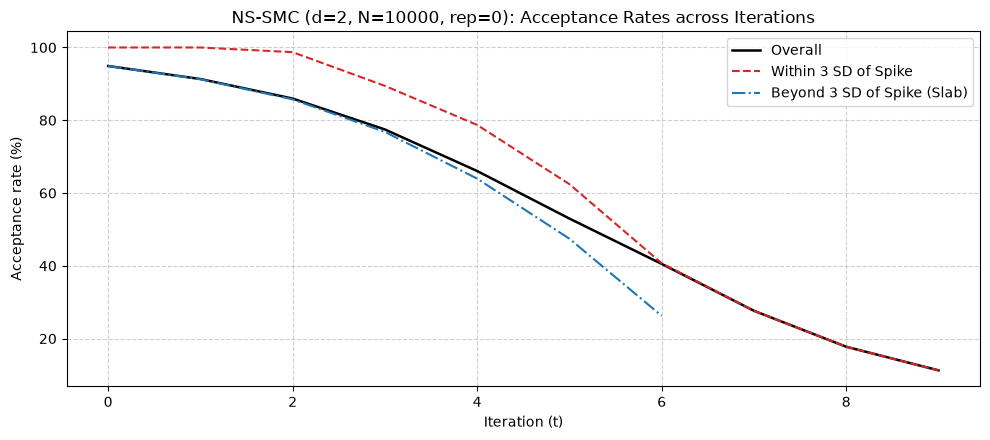

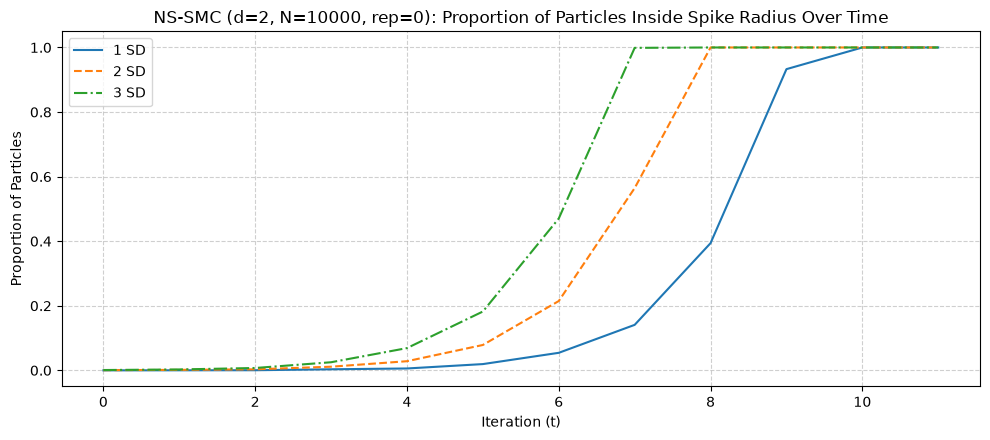

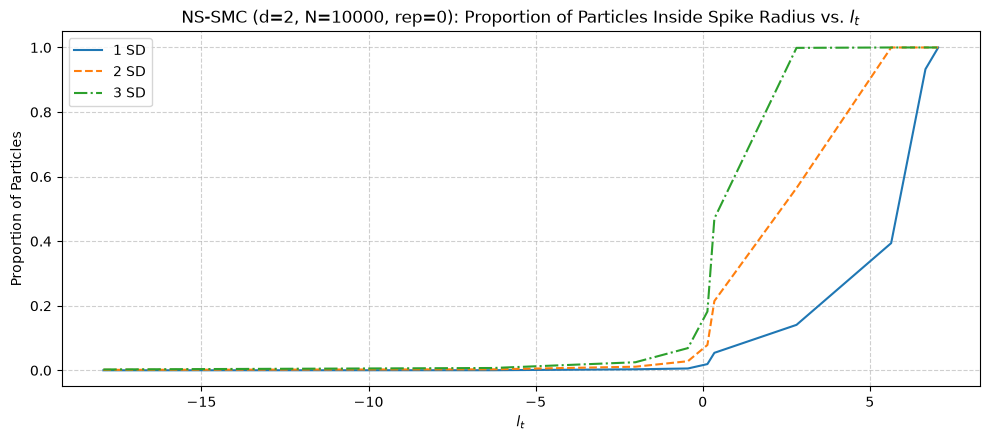

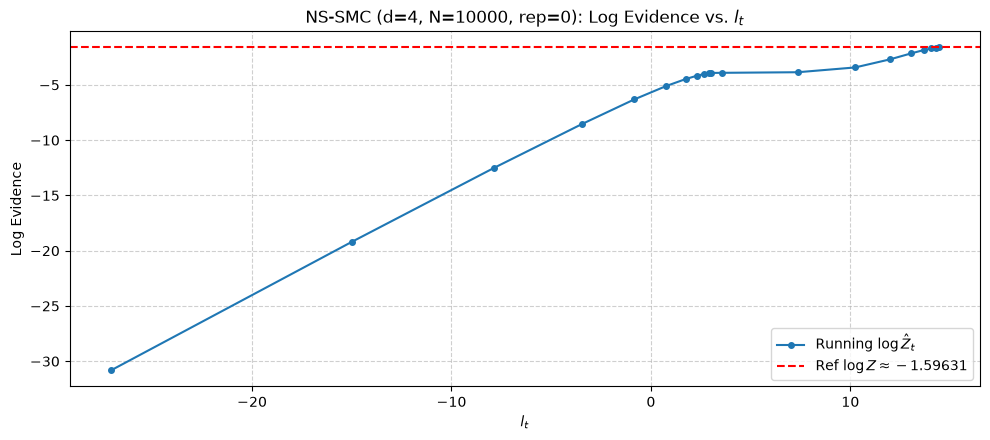

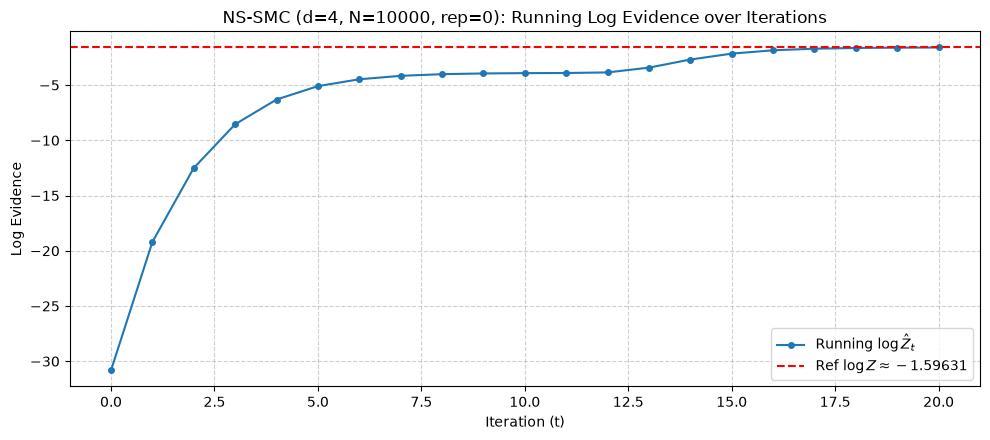

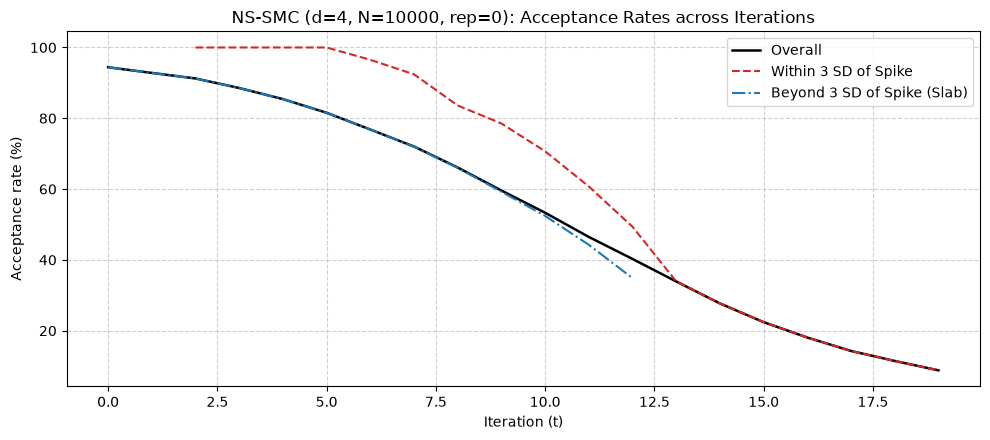

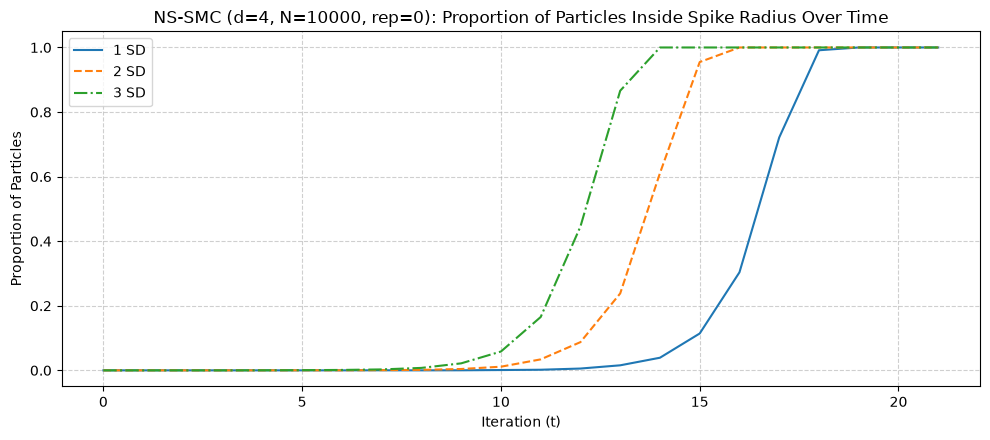

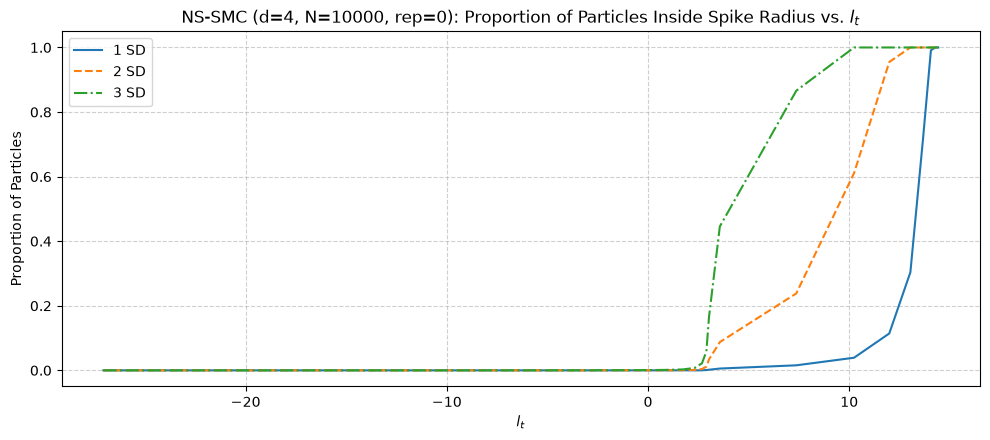

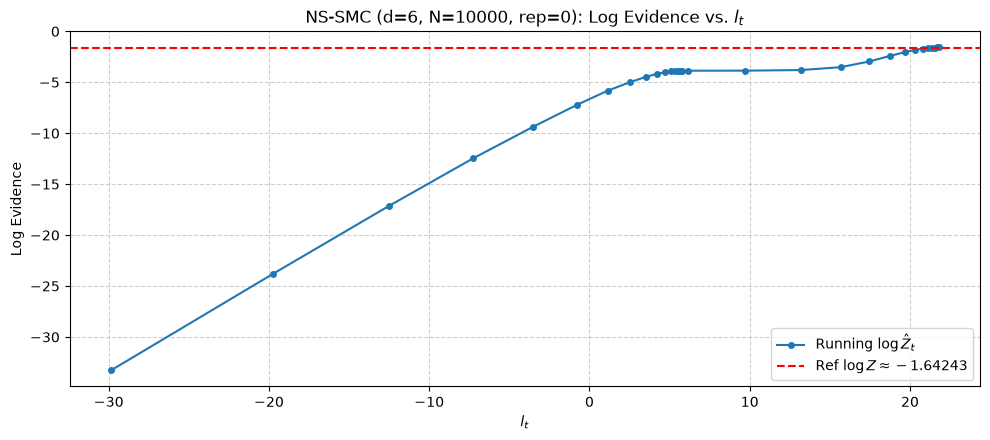

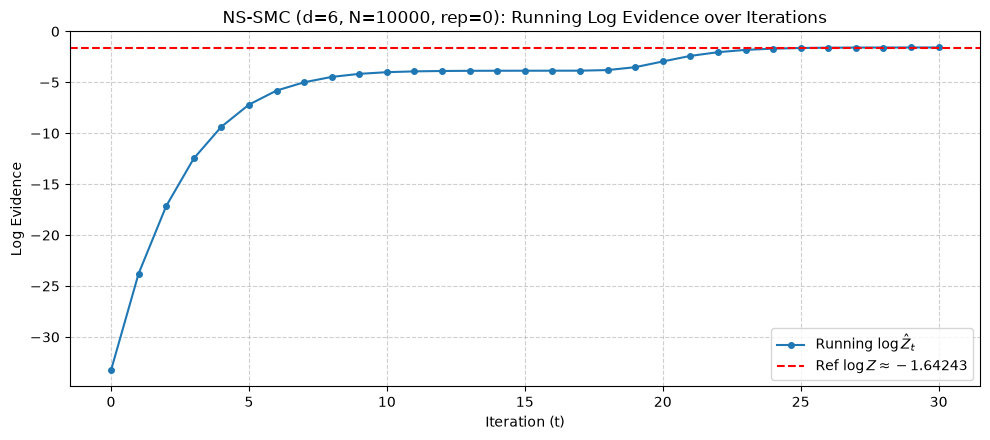

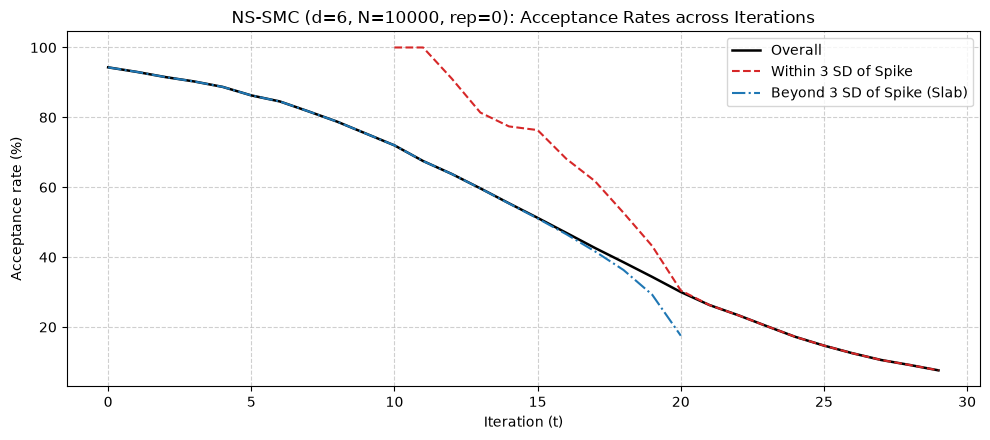

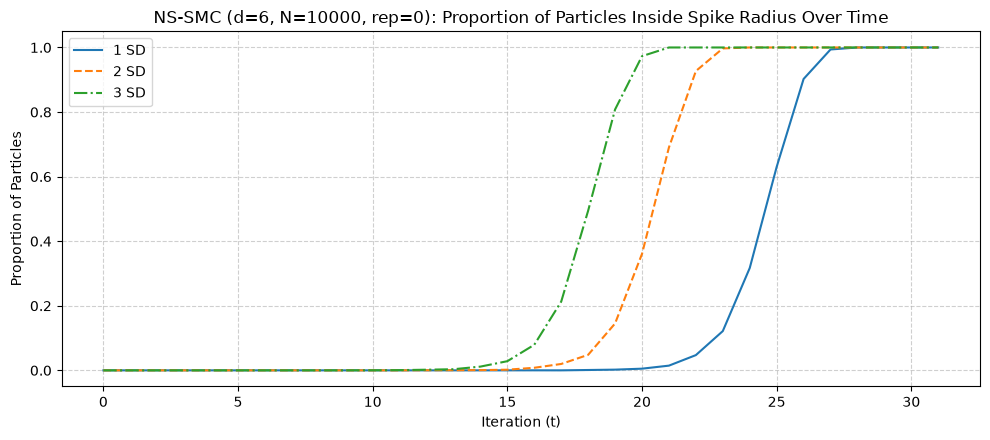

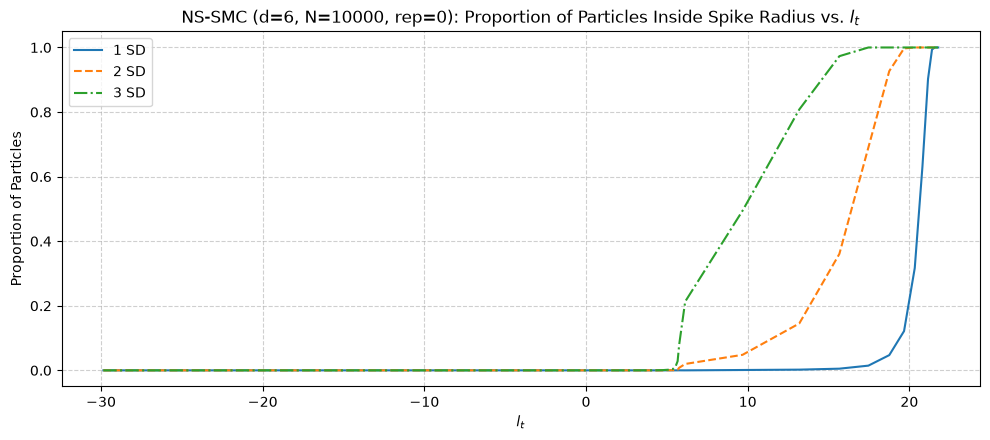

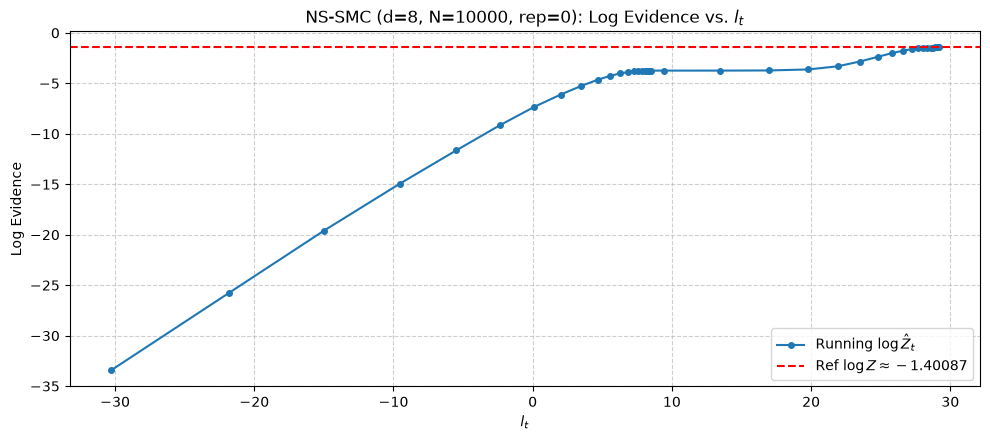

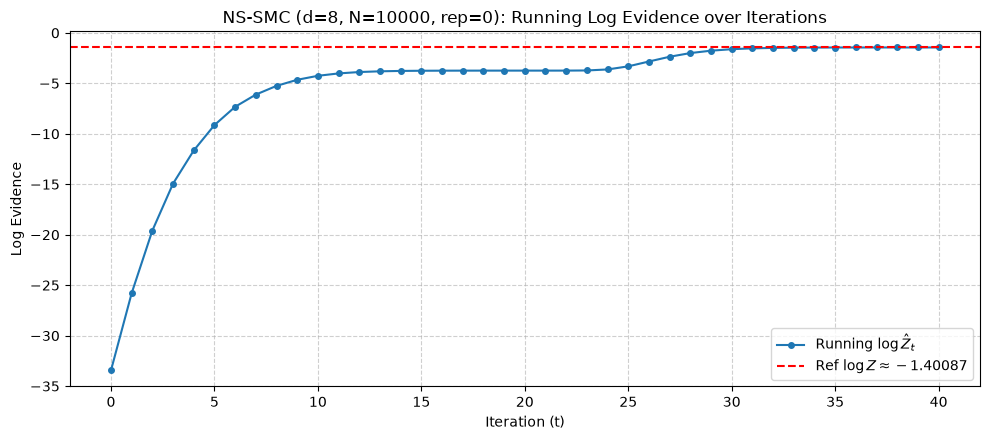

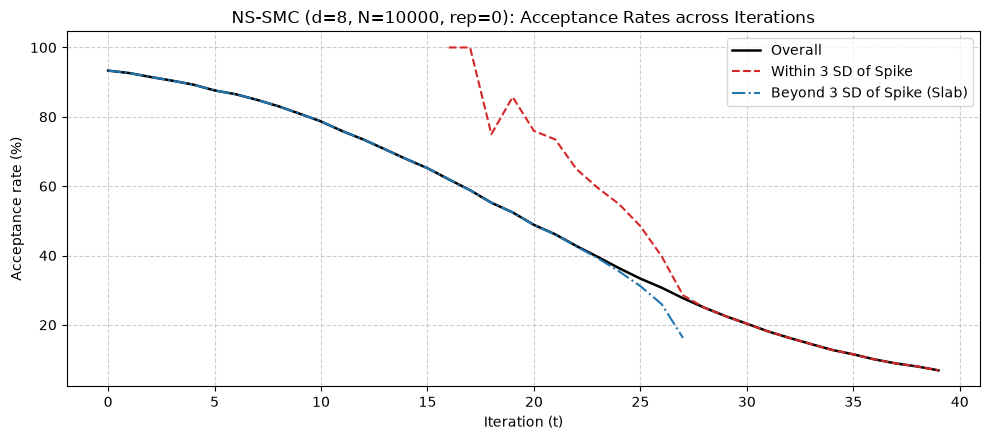

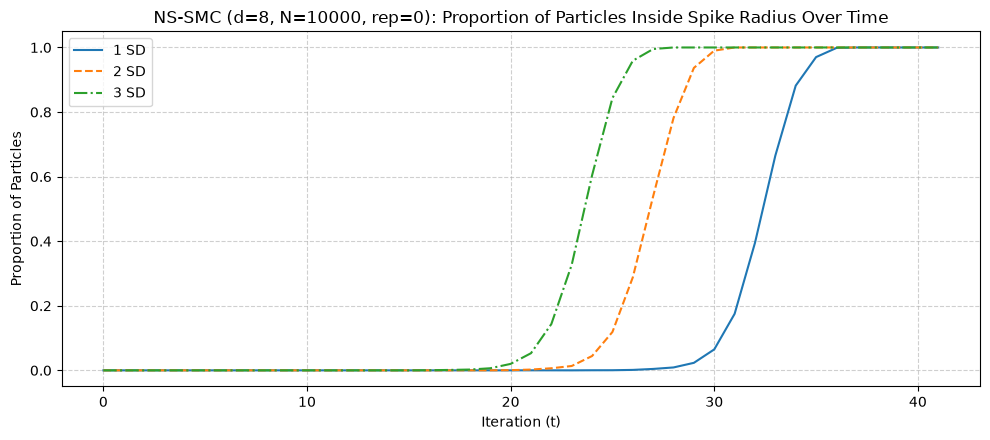

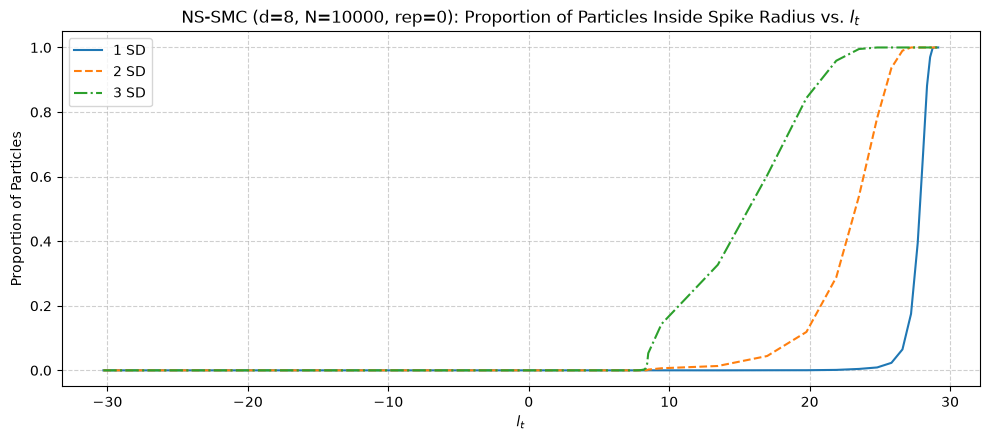

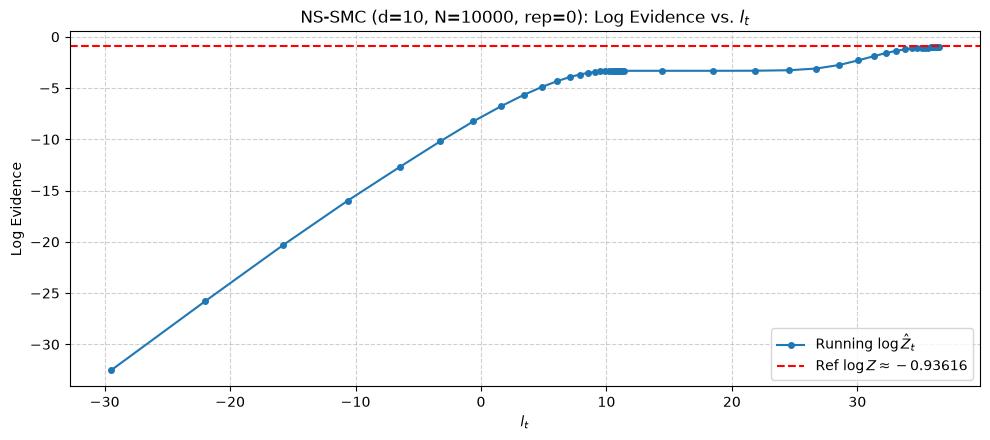

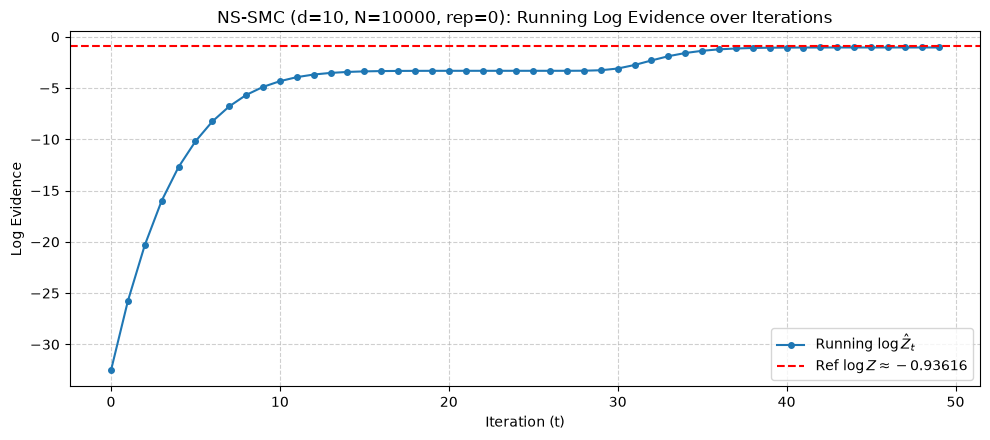

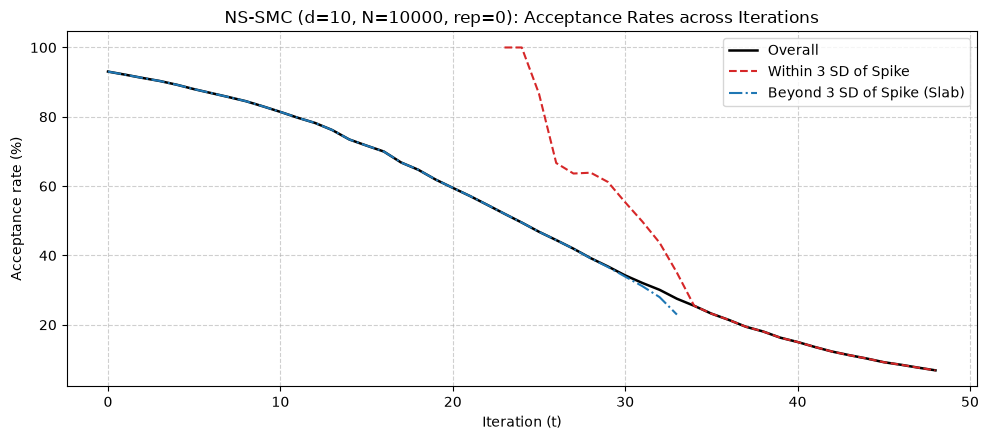

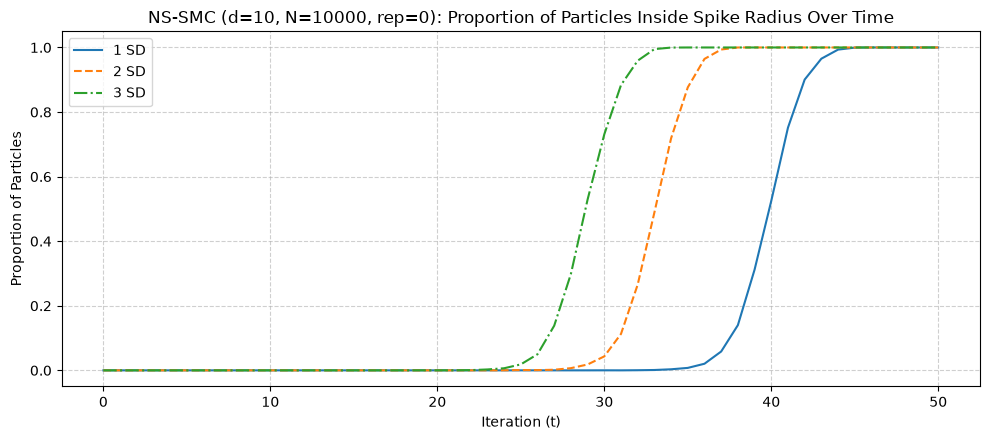

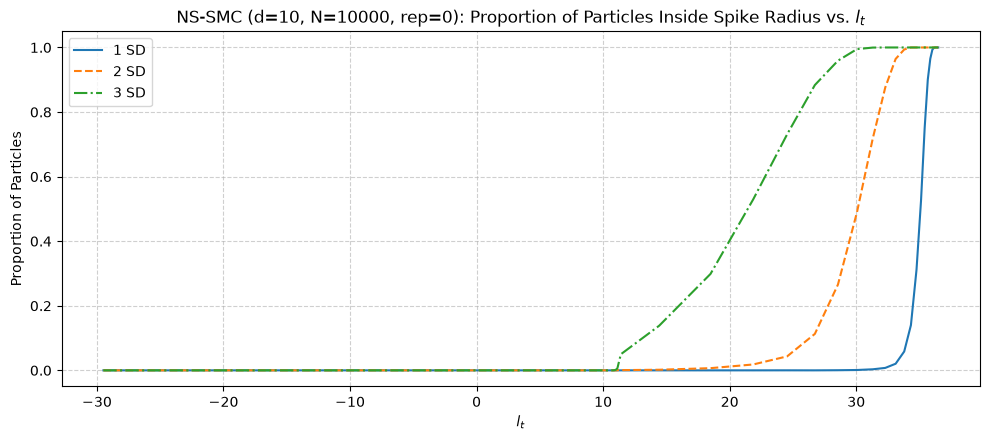

In [41]:
df_ns_smc = pd.concat(
    [
        run_ns_smc_for_d(d_val, levels_ans_smc, ans_meta_by_run, num_repeats=num_repeats, plot_diagnostics=True)
        for d_val in dims
    ],
    ignore_index=True,
)

In [42]:
df_ns_smc["true_Z"] = df_ns_smc["d"].map(z_by_d)
df_ns_smc["true_log_Z"] = df_ns_smc["d"].map(log_z_by_d)
df_ns_smc["abs_error"] = np.sqrt((df_ns_smc["Z"] - df_ns_smc["true_Z"]) ** 2)
df_ns_smc[["d", "log_evidence", "true_log_Z", "Z", "true_Z", "abs_error", "total_prop_spike", "total_prop_slab"]]

,d,log_evidence,true_log_Z,Z,true_Z,abs_error,total_prop_spike,total_prop_slab
0,2,-1.110735,-1.144730,0.329317,0.318310,0.011007,100000,0
1,4,-1.598029,-1.596313,0.202295,0.202642,0.000347,100000,0
2,6,-1.582134,-1.642430,0.205536,0.193509,0.012027,100000,0
3,8,-1.448695,-1.400866,0.234877,0.246383,0.011507,100000,0
4,10,-1.043047,-0.936158,0.352379,0.392131,0.039752,100000,0


# $\alpha=0.9$

## ANS-SMC

d=2


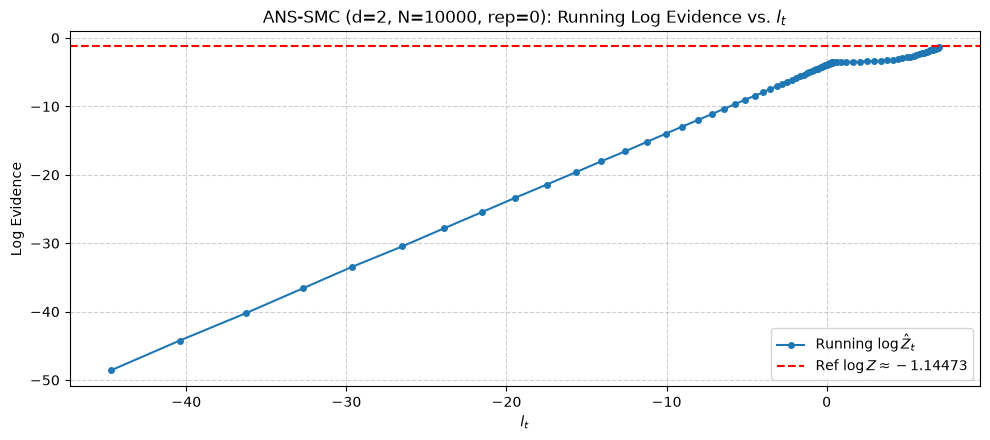

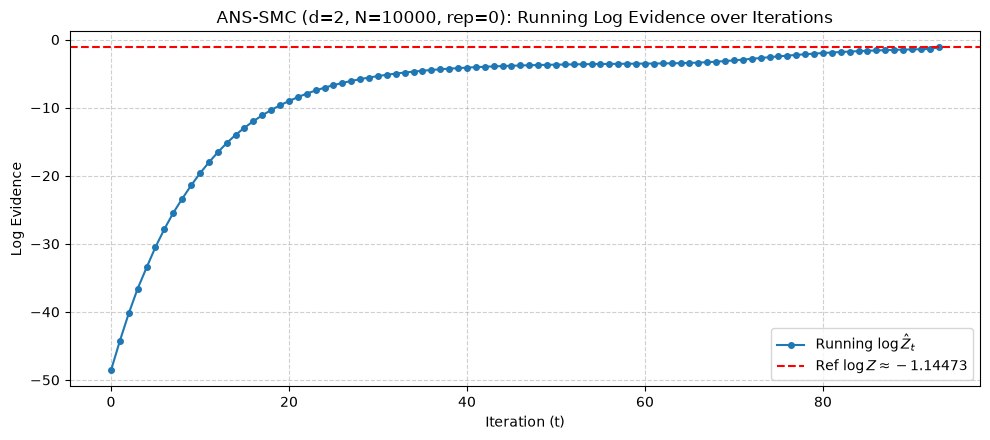

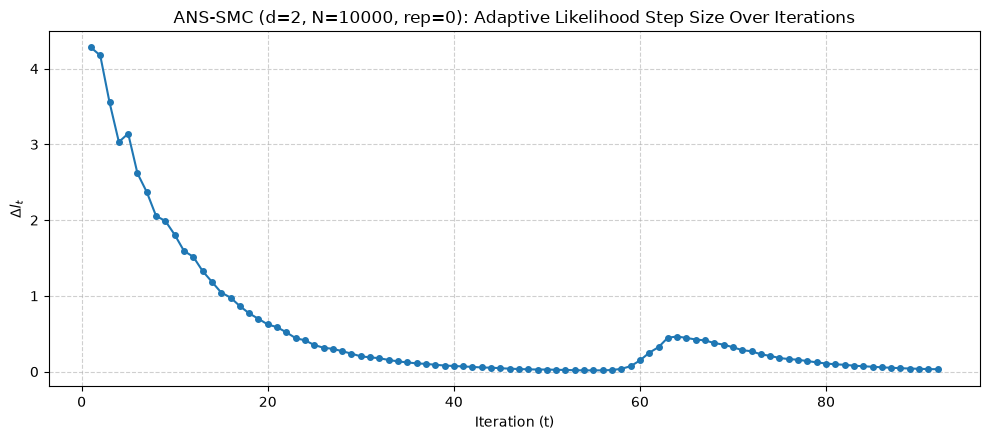

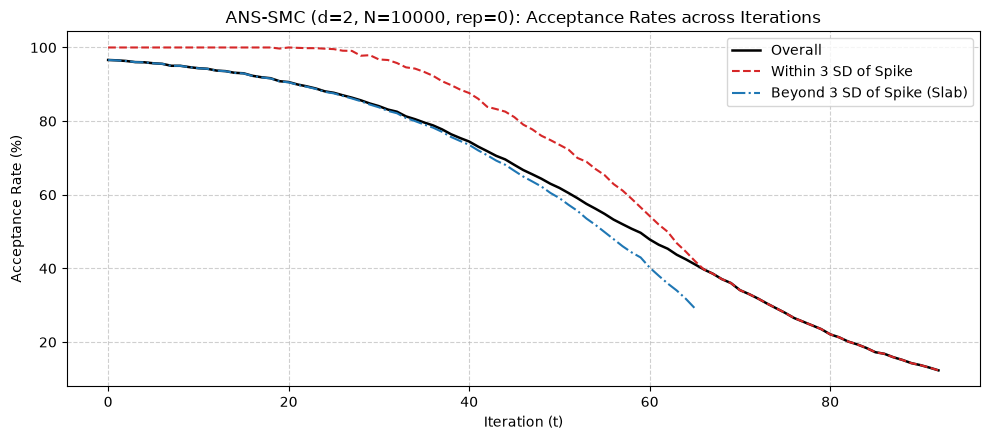

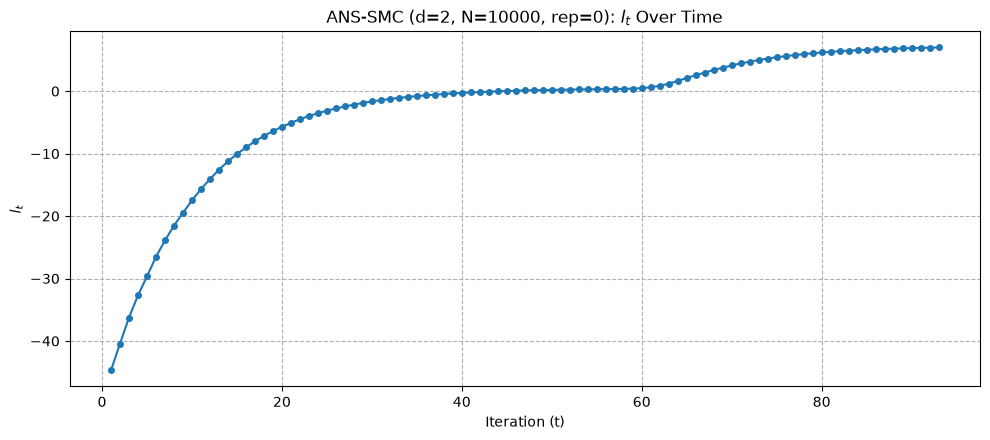

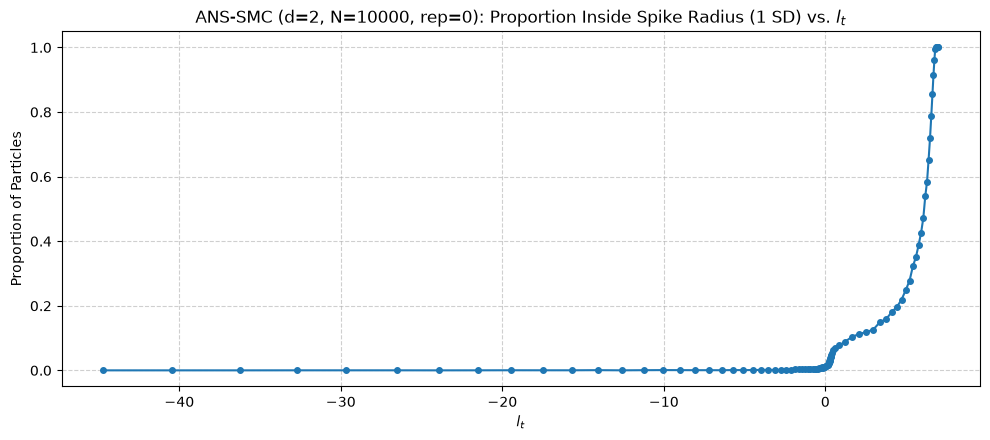

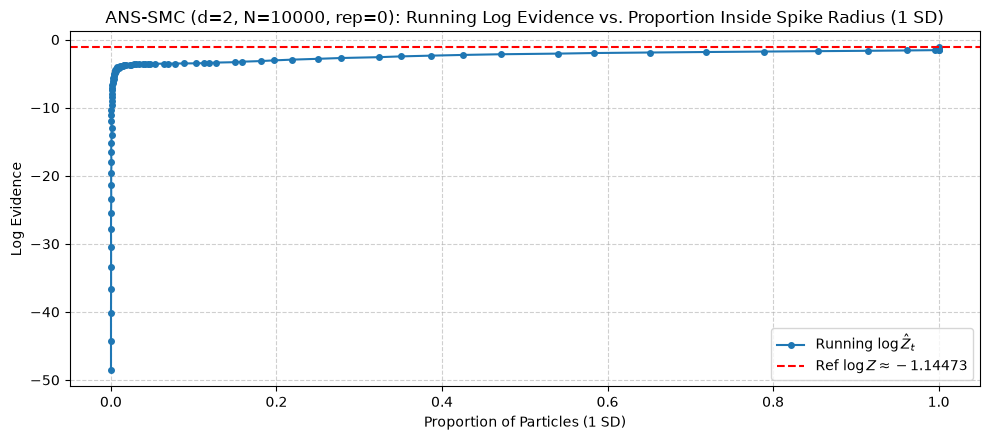

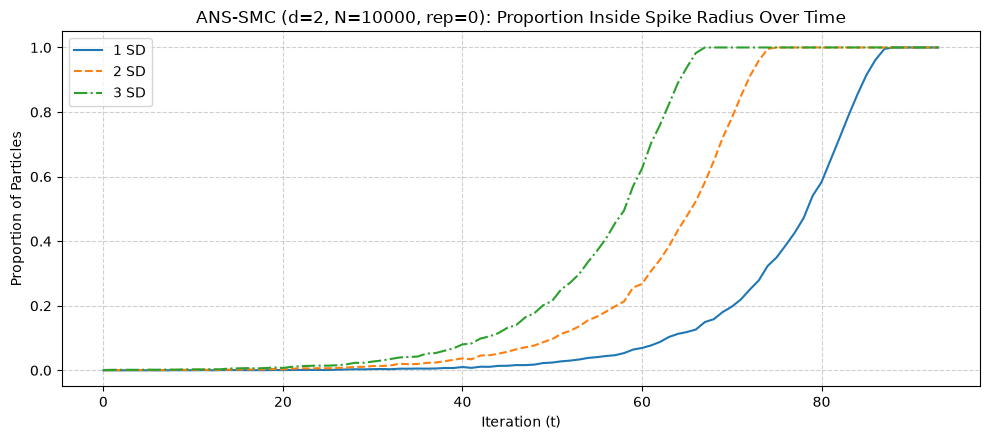

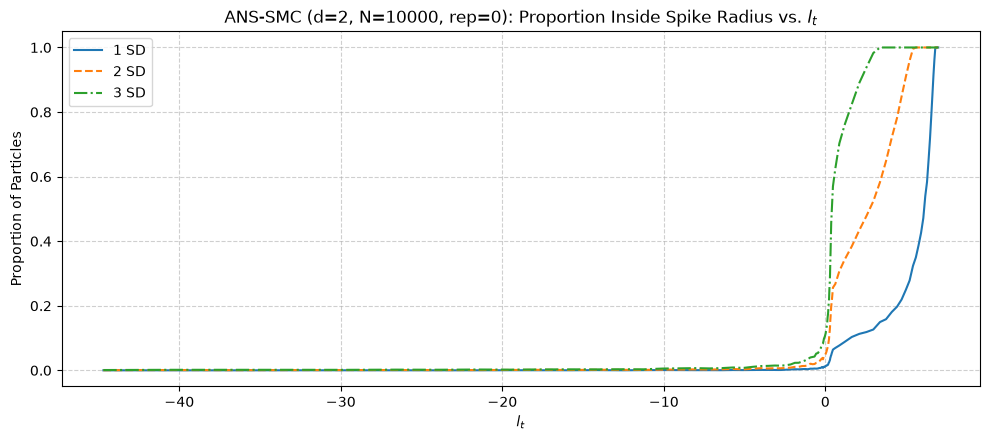

d=4


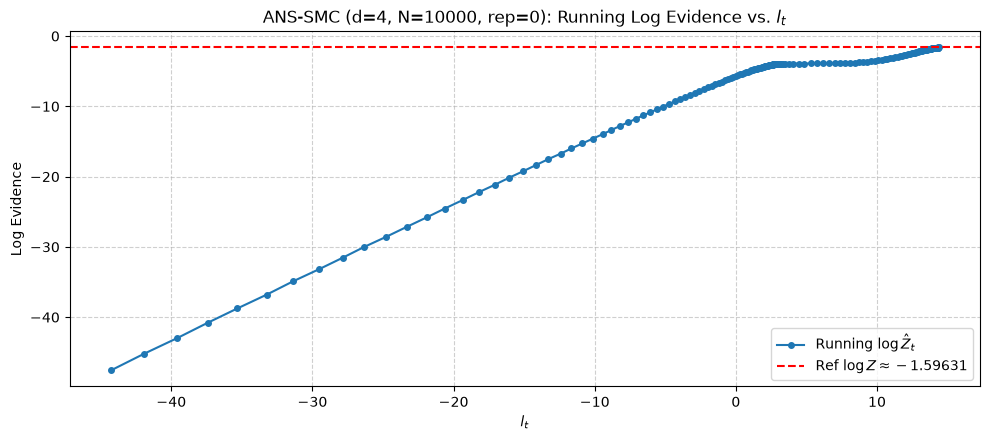

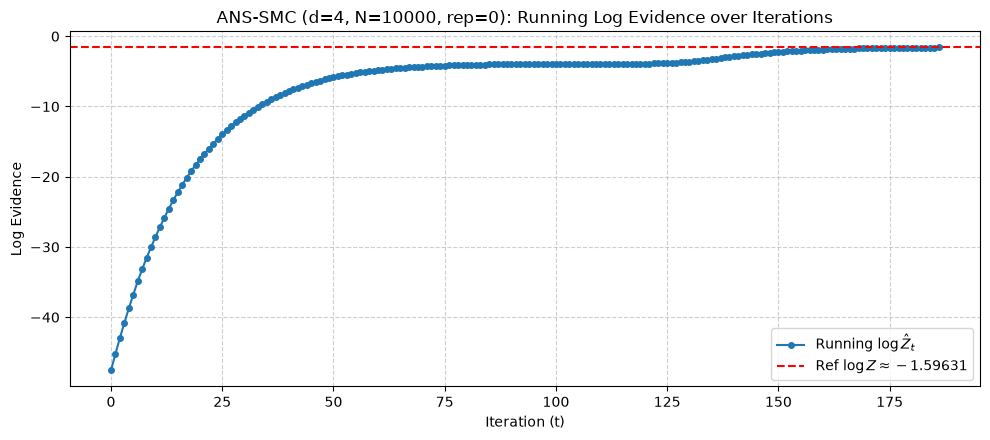

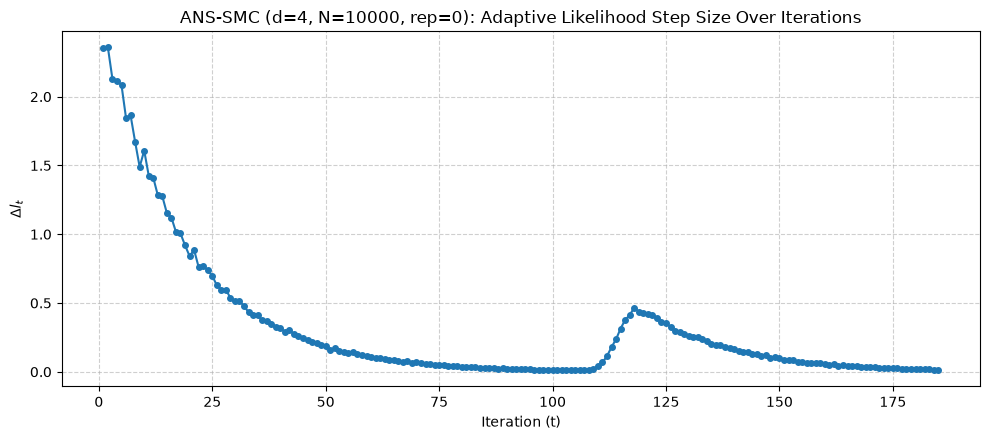

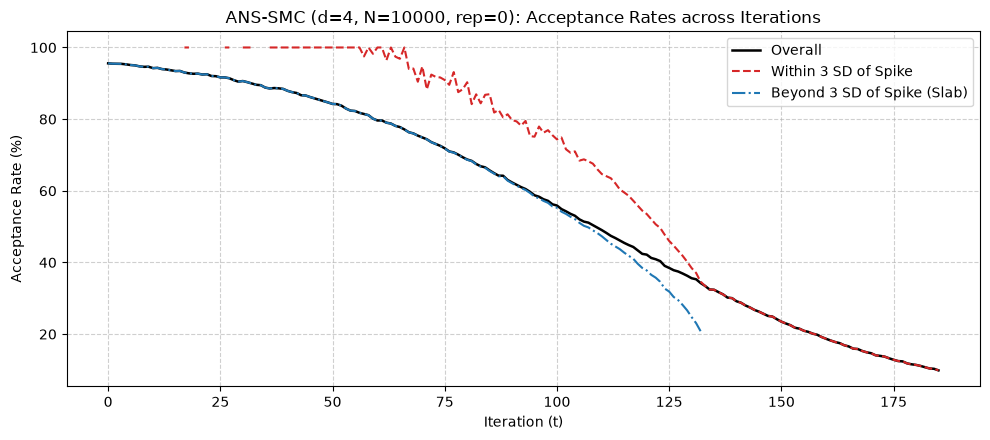

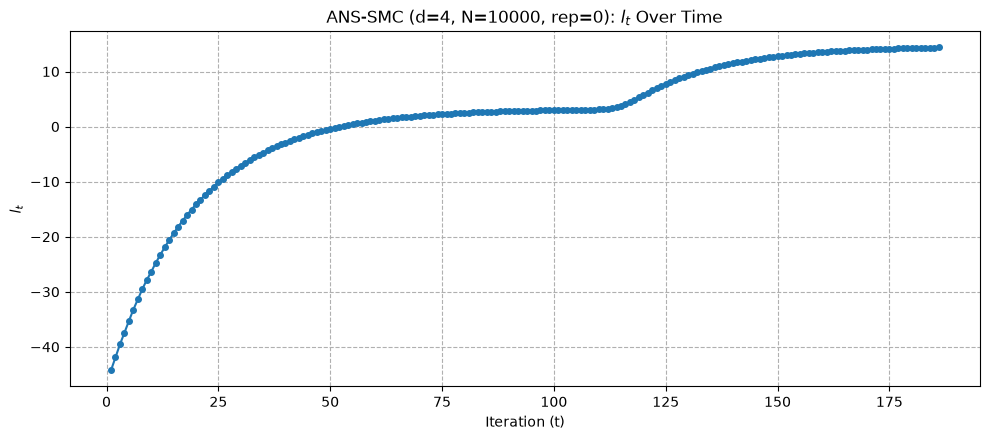

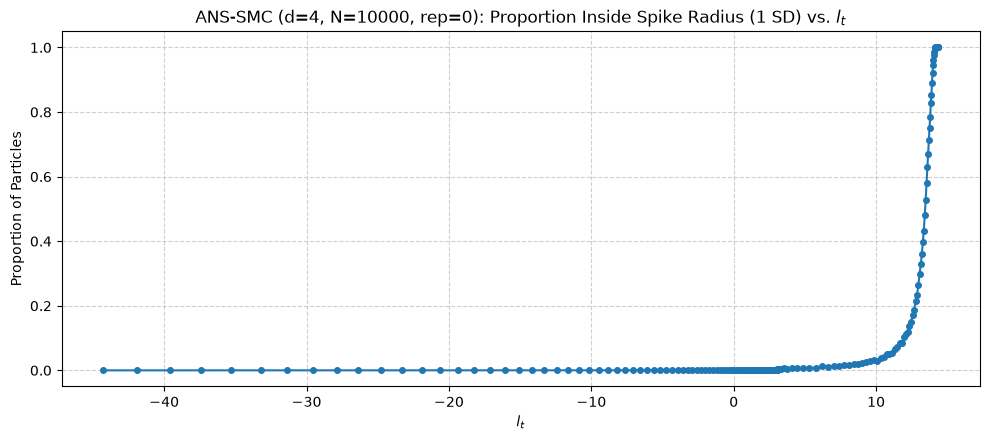

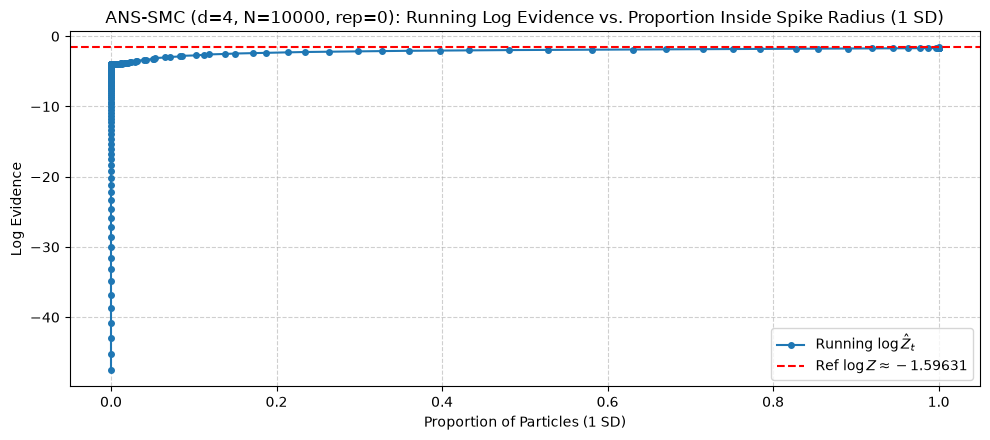

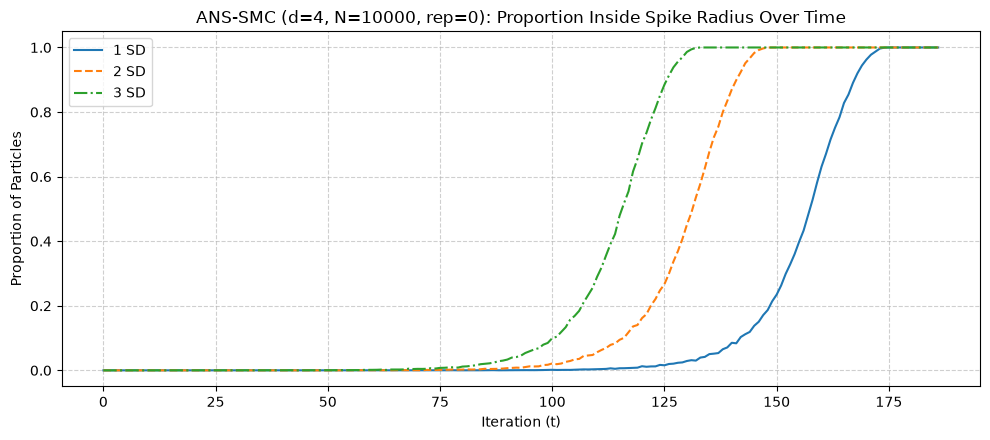

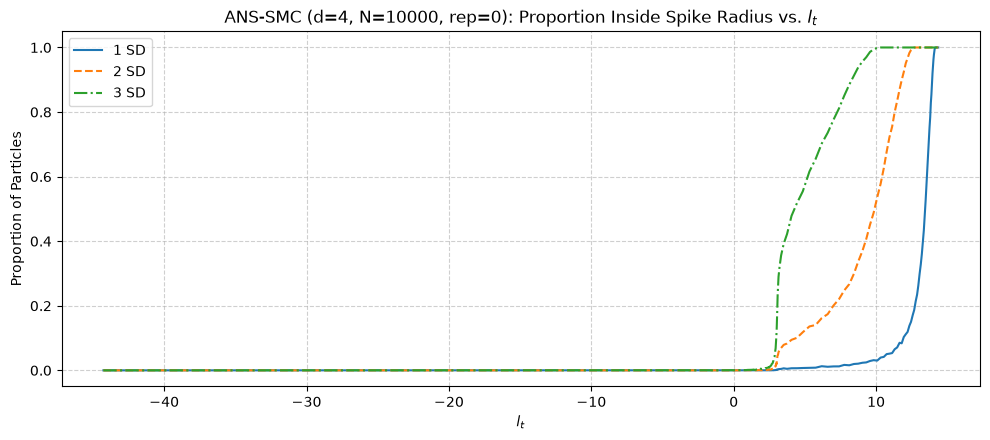

d=6


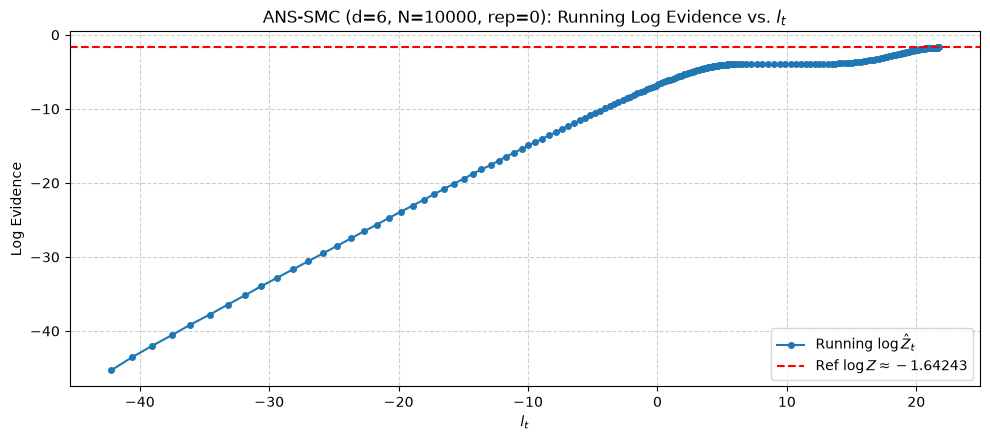

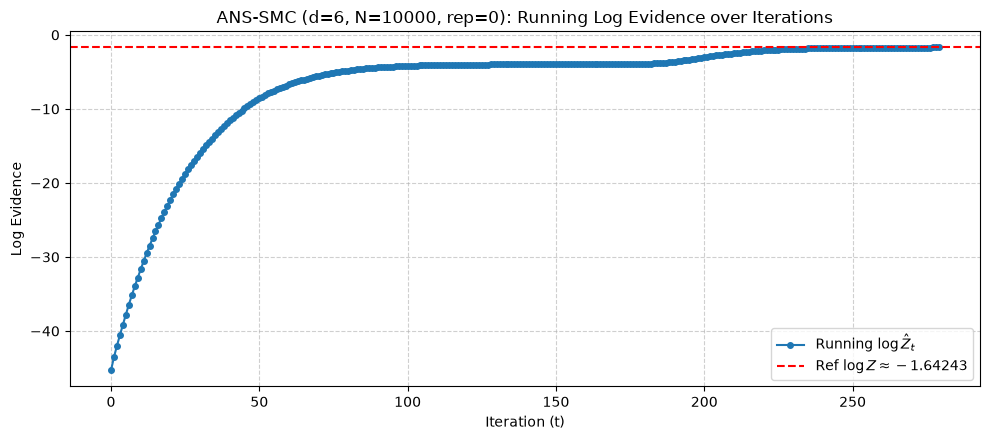

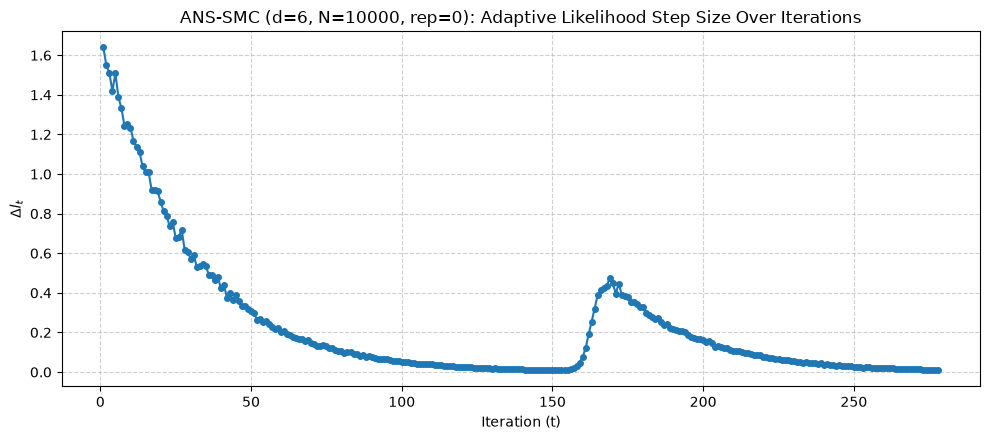

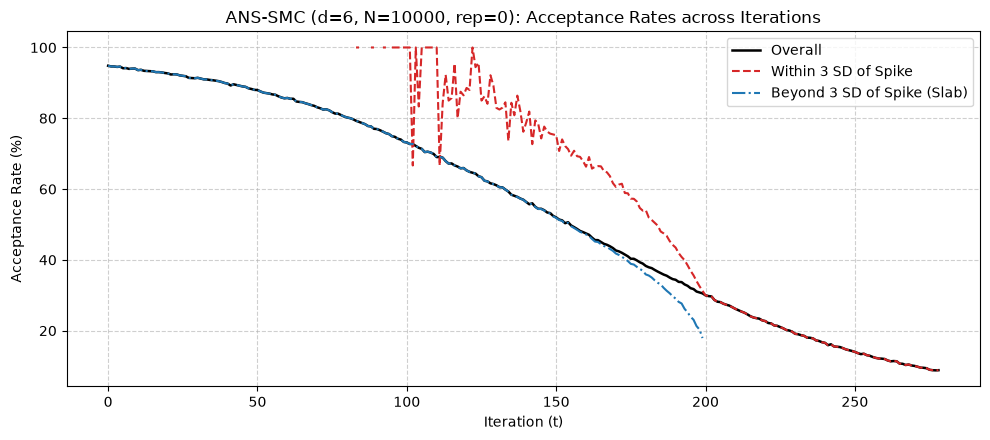

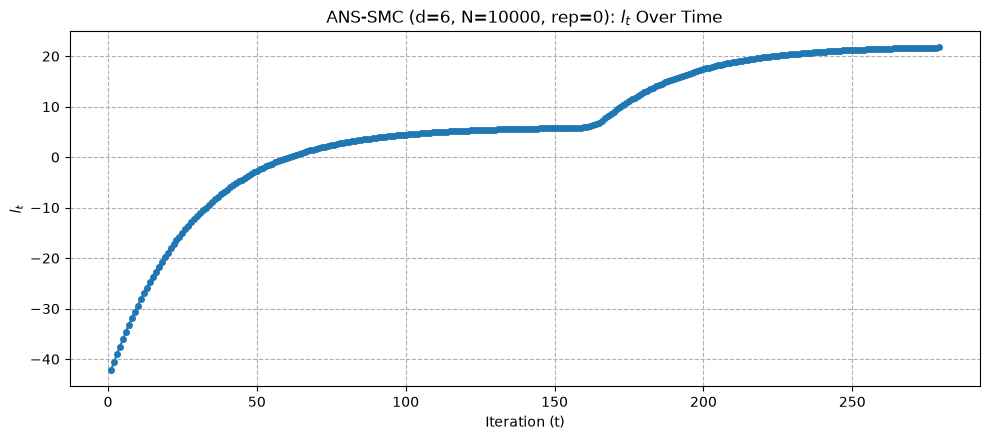

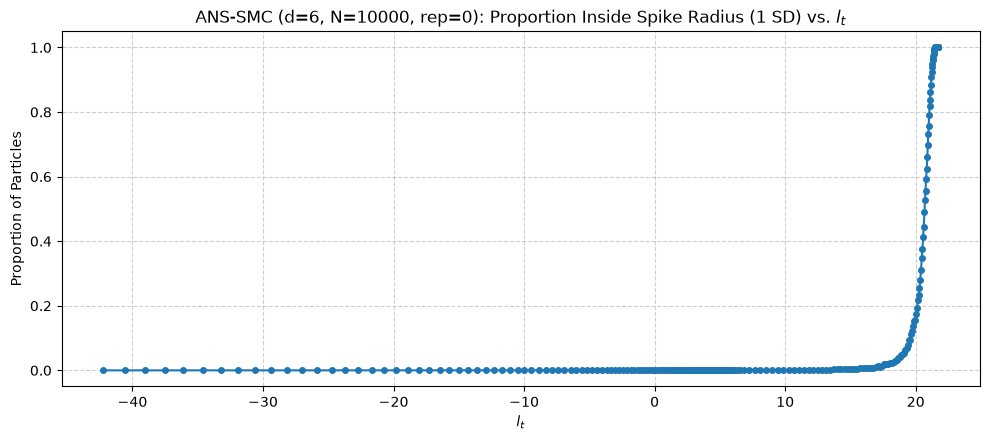

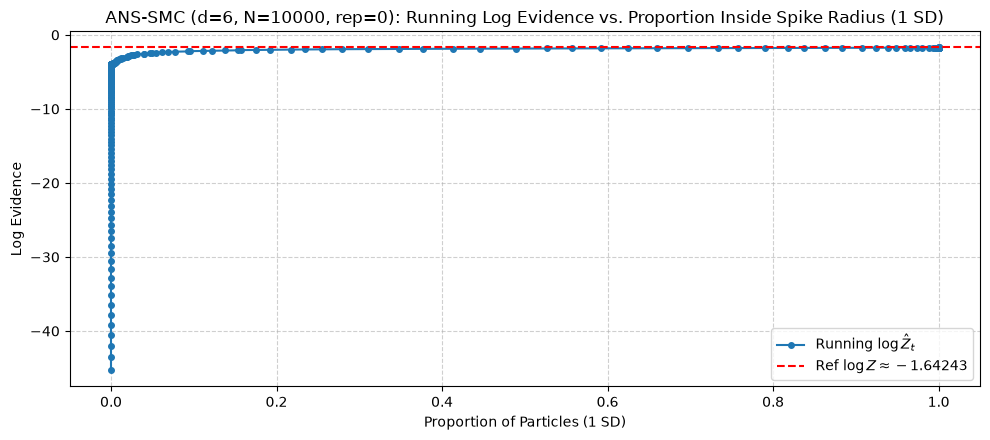

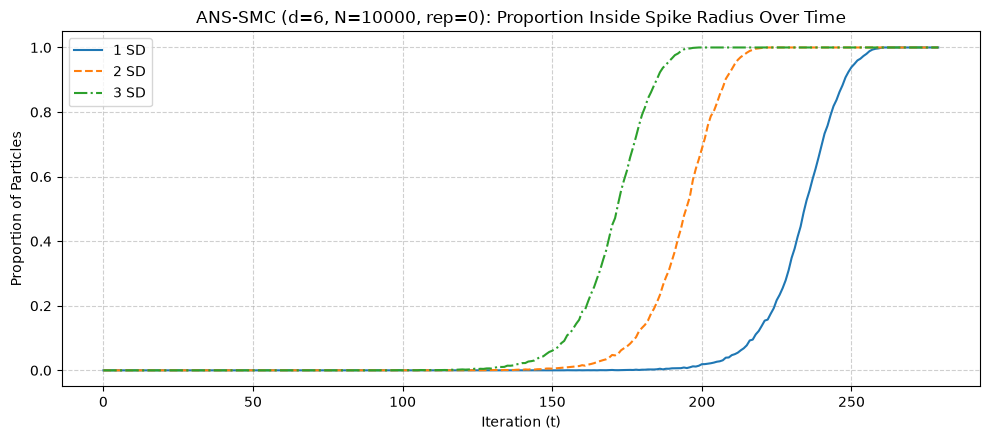

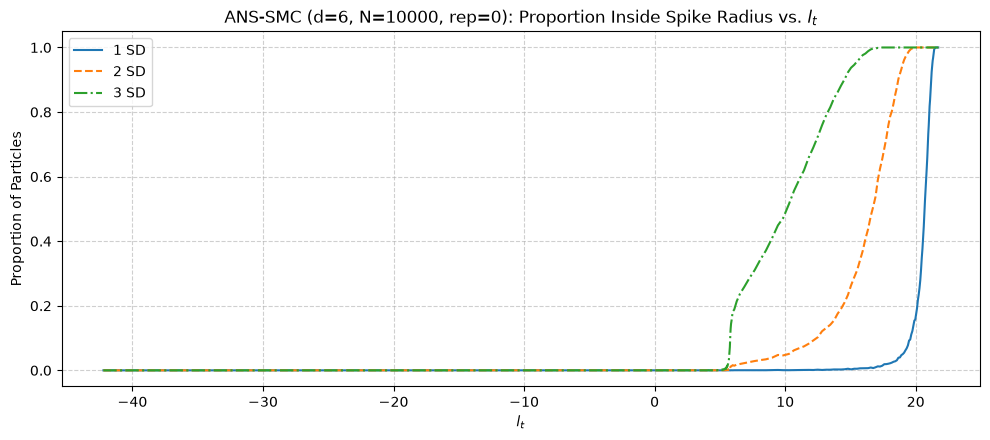

d=8


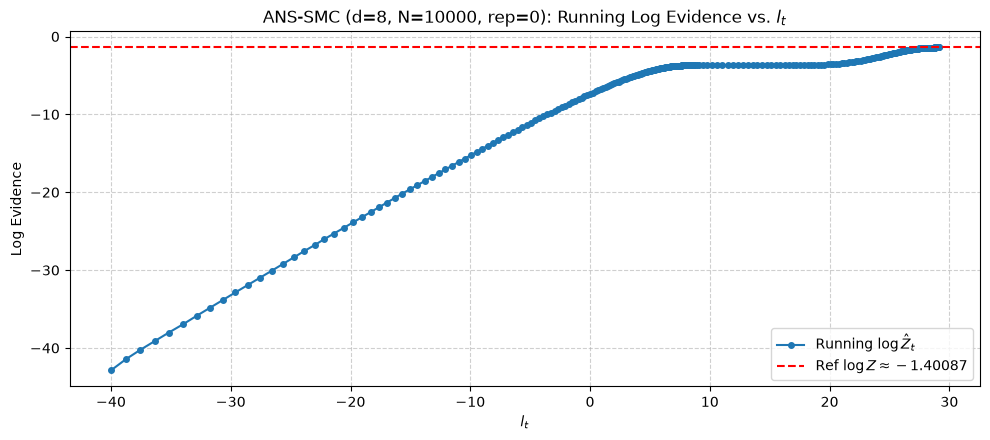

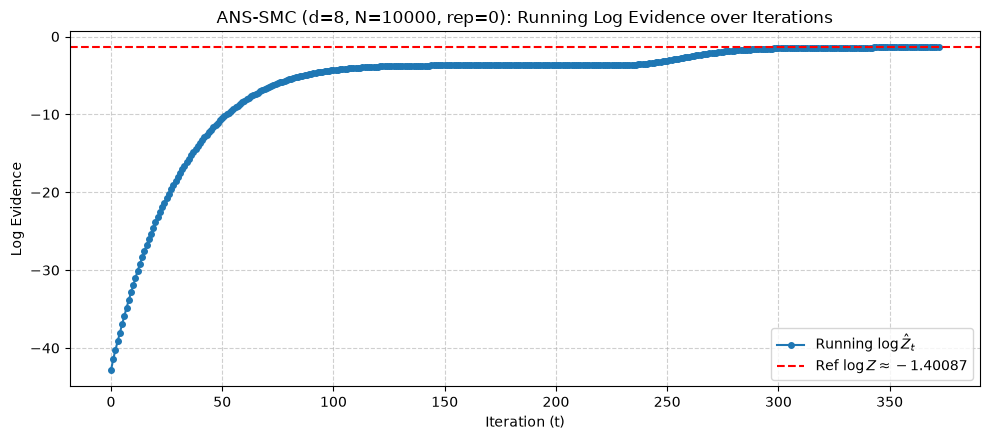

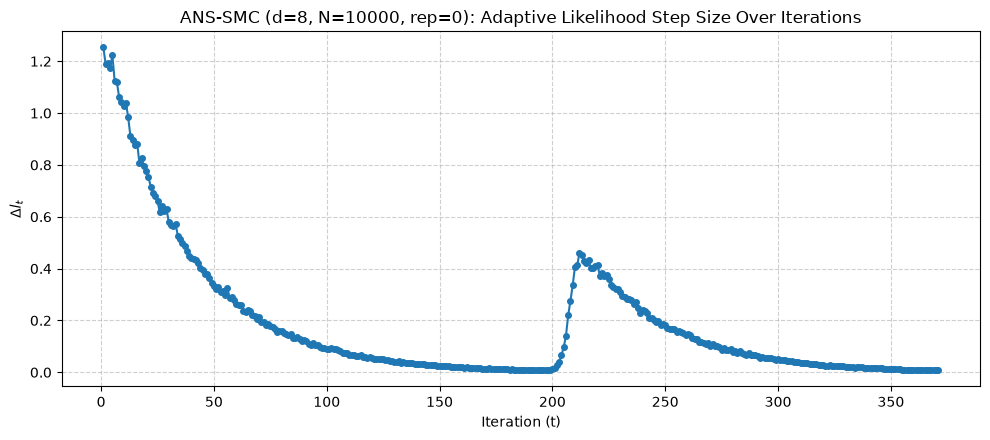

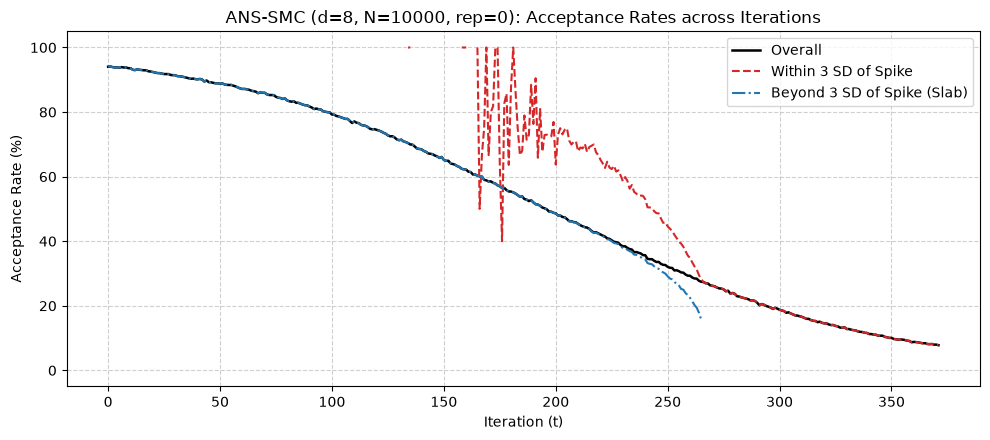

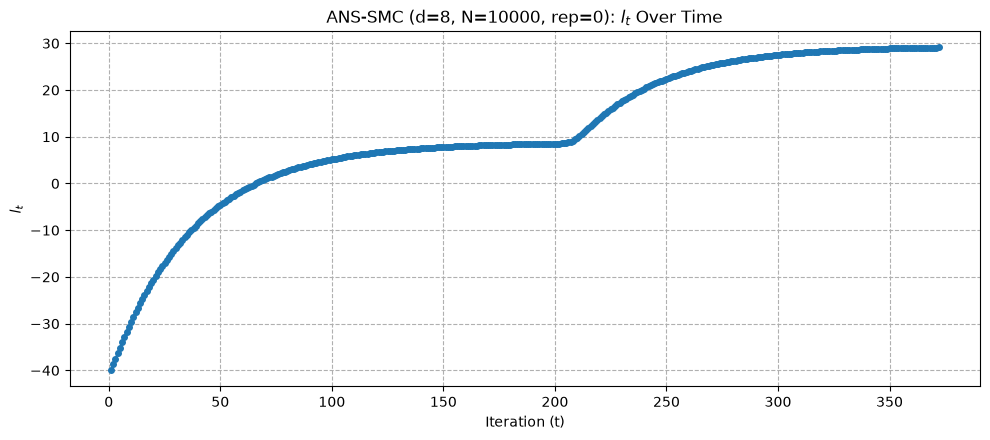

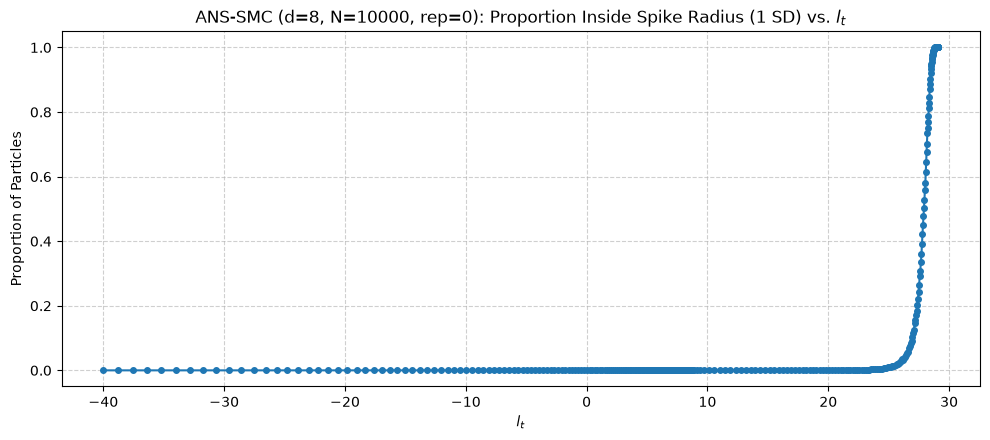

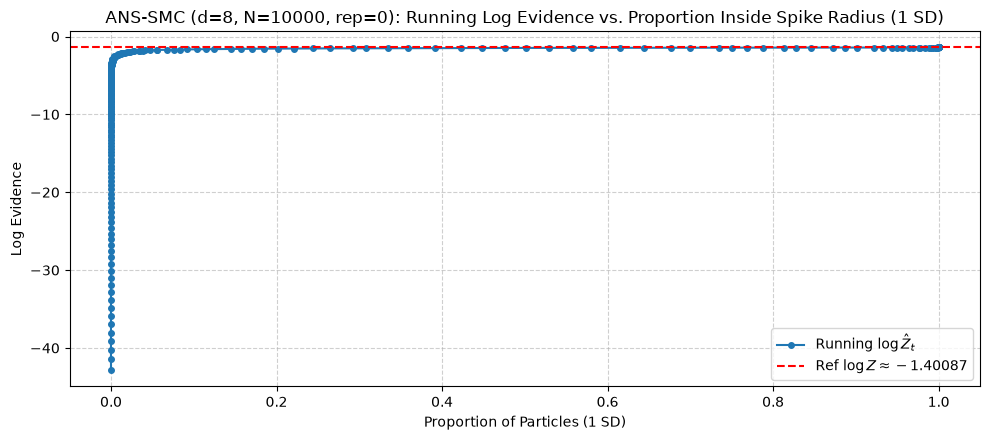

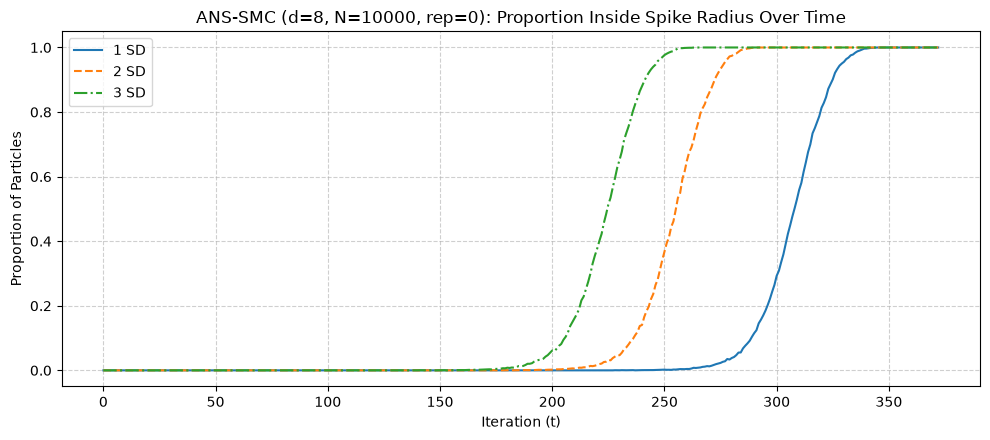

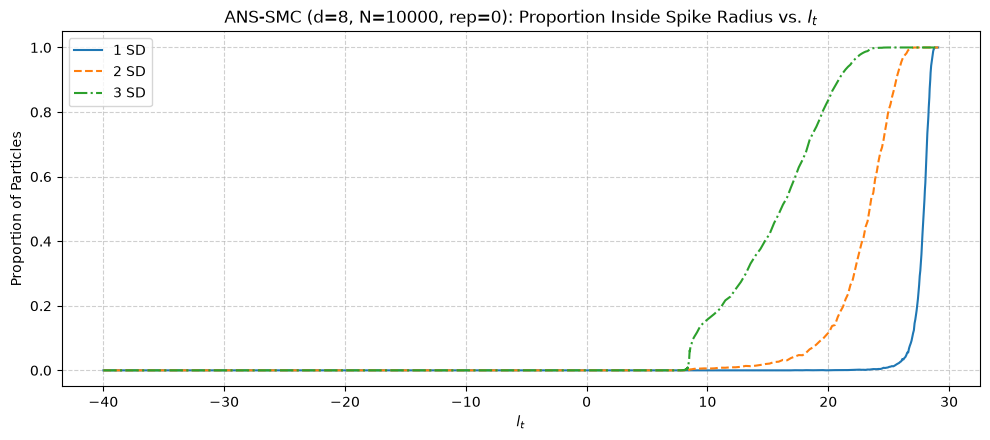

d=10


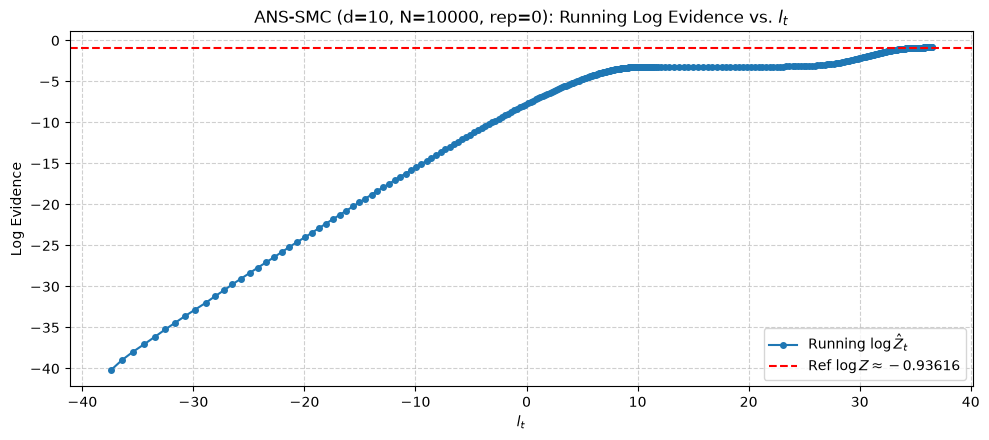

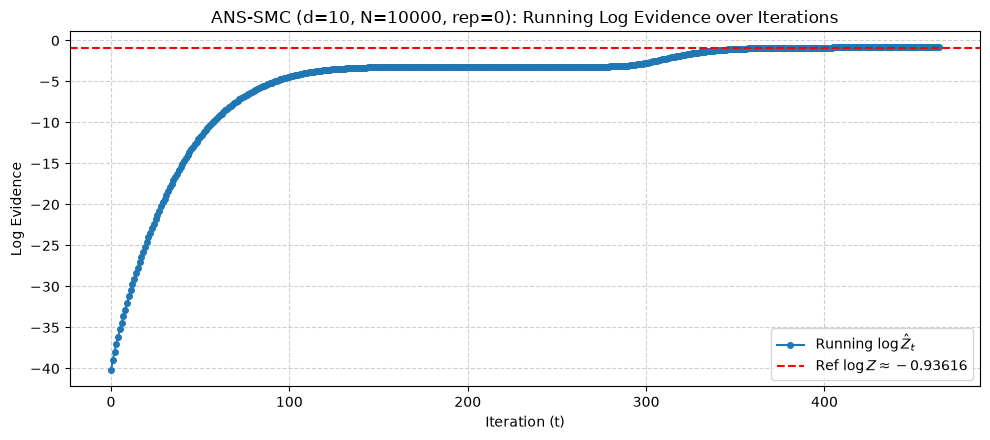

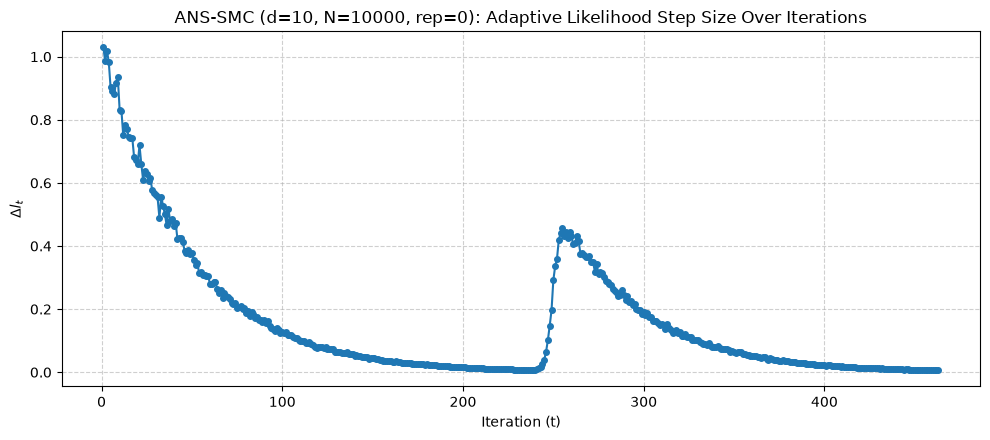

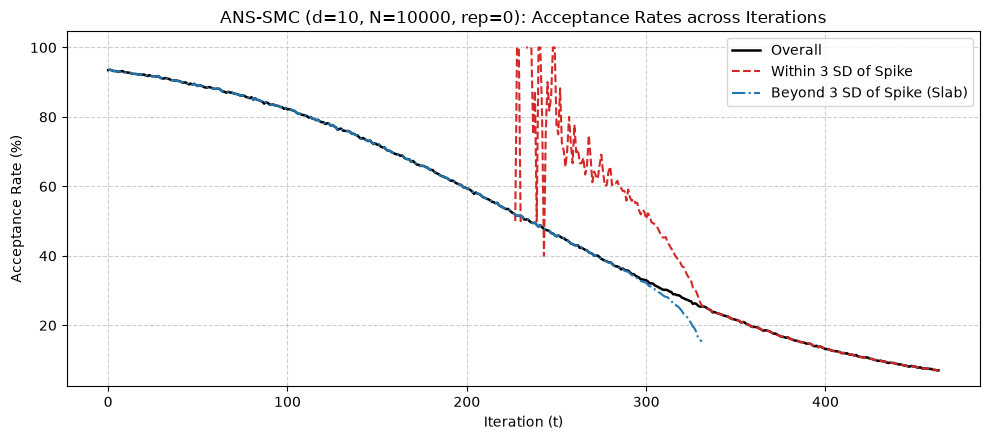

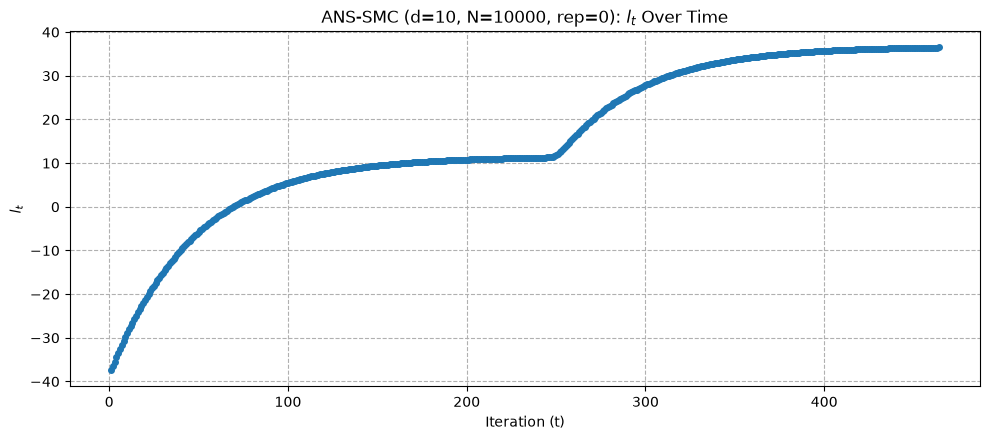

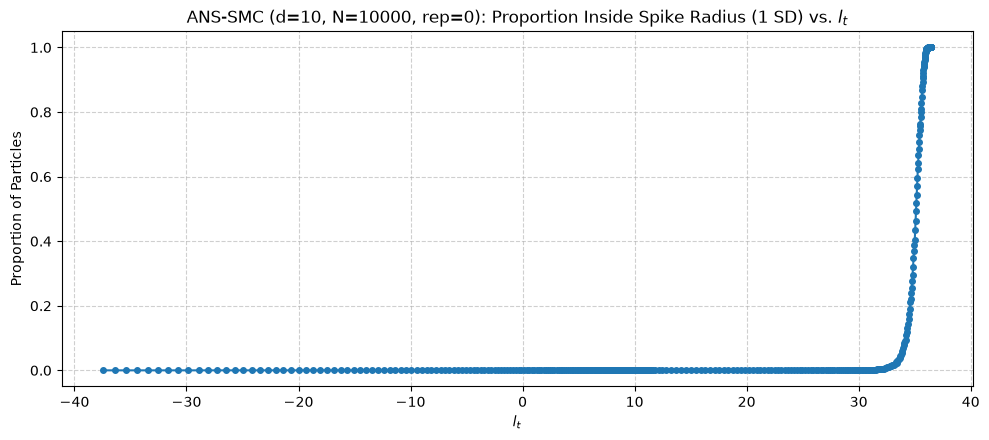

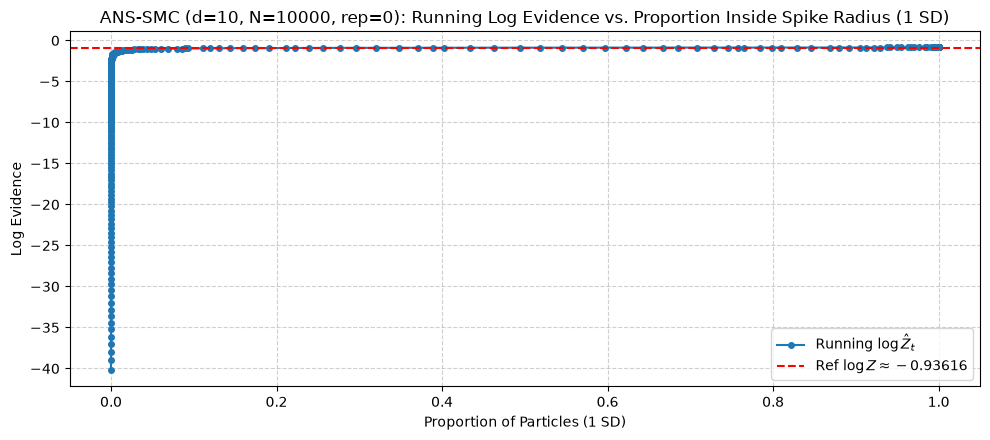

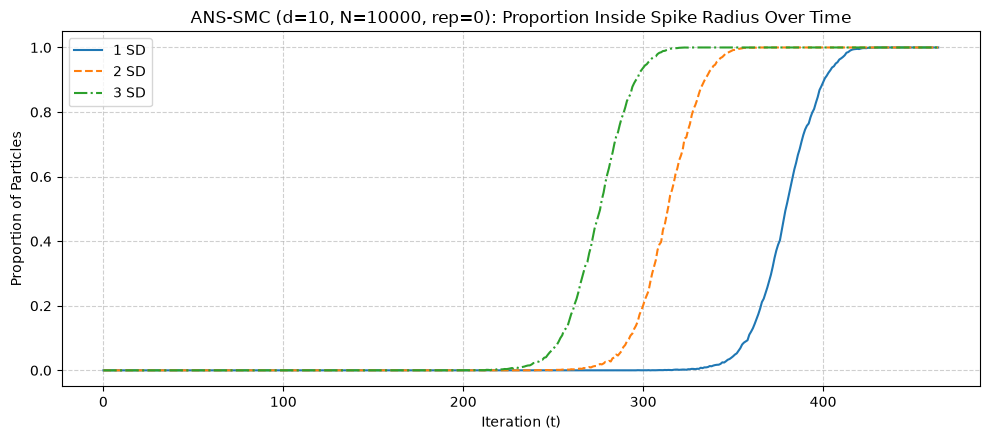

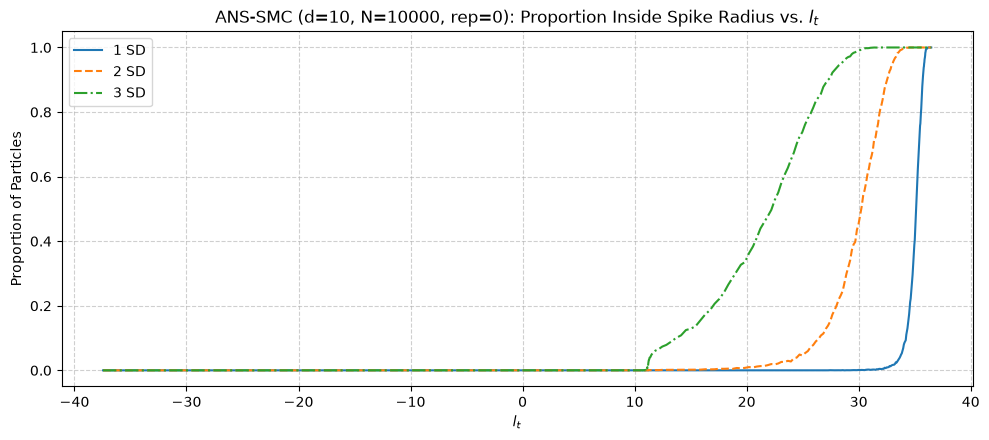

In [43]:
dims = [2, 4, 6, 8, 10]
N = 10000
alpha = 0.9
repeats = 10
num_repeats = 1

df_ans_smc_2, levels_ans_smc_2, ans_meta_by_run_2 = run_all_ans_smc(
    dims, alpha=0.9, num_repeats=num_repeats, plot_diagnostics=True
)

In [45]:
df_ans_smc_2["true_Z"] = df_ans_smc_2["d"].map(z_by_d)
df_ans_smc_2["true_log_Z"] = df_ans_smc_2["d"].map(log_z_by_d)
df_ans_smc_2["abs_error"] = np.sqrt((df_ans_smc_2["Z"] - df_ans_smc_2["true_Z"]) ** 2)
df_ans_smc_2[["d", "log_evidence", "true_log_Z", "Z", "true_Z", "abs_error", "total_prop_spike", "total_prop_slab"]]

,d,log_evidence,true_log_Z,Z,true_Z,abs_error,total_prop_spike,total_prop_slab
0,2,-1.160100,-1.144730,0.313455,0.318310,0.004855,100000,0
1,4,-1.596515,-1.596313,0.202601,0.202642,0.000041,100000,0
2,6,-1.704613,-1.642430,0.181843,0.193509,0.011666,100000,0
3,8,-1.409469,-1.400866,0.244273,0.246383,0.002111,100000,0
4,10,-0.857636,-0.936158,0.424163,0.392131,0.032032,100000,0


## NS-SMC

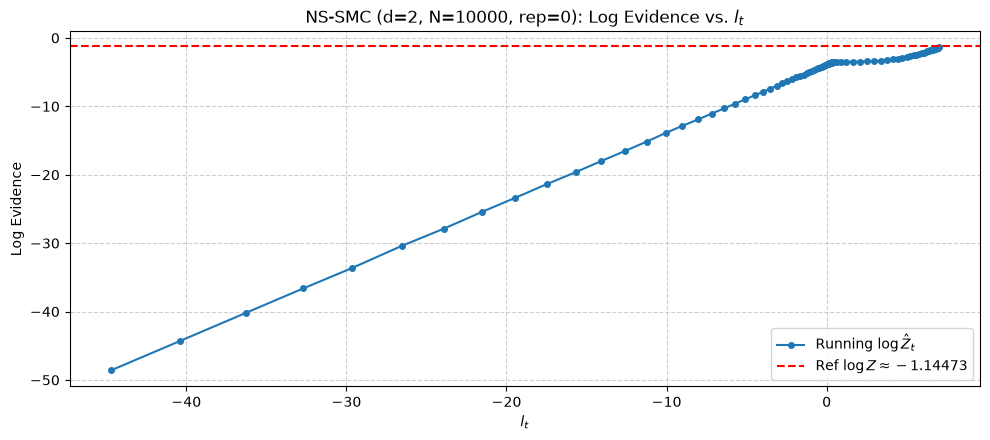

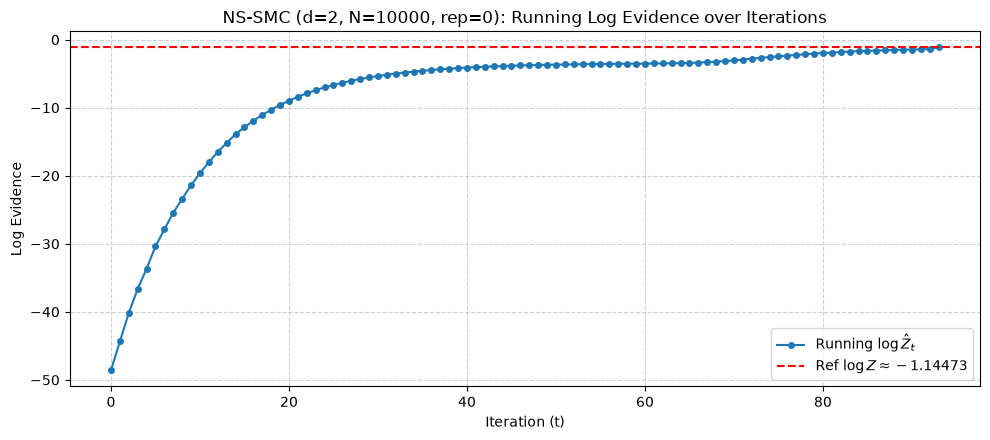

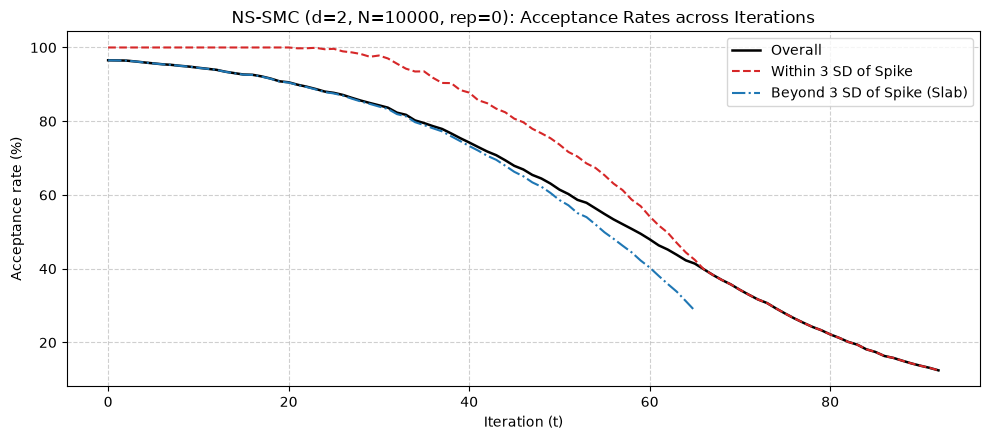

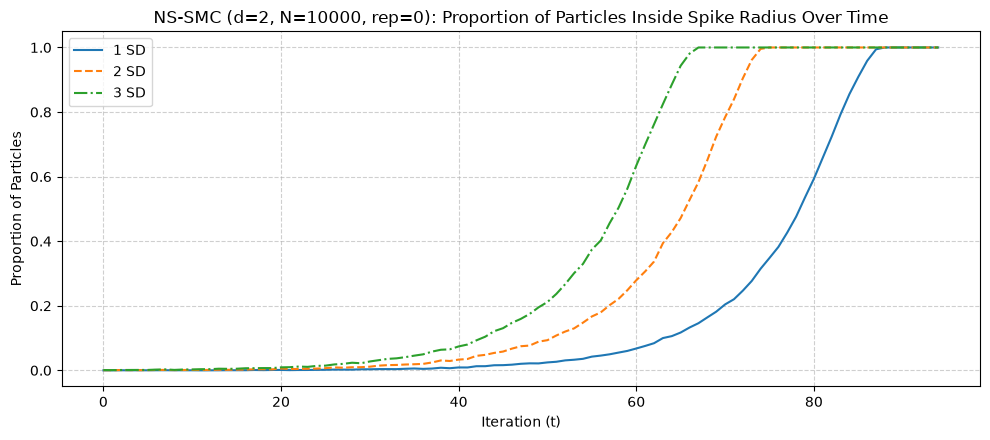

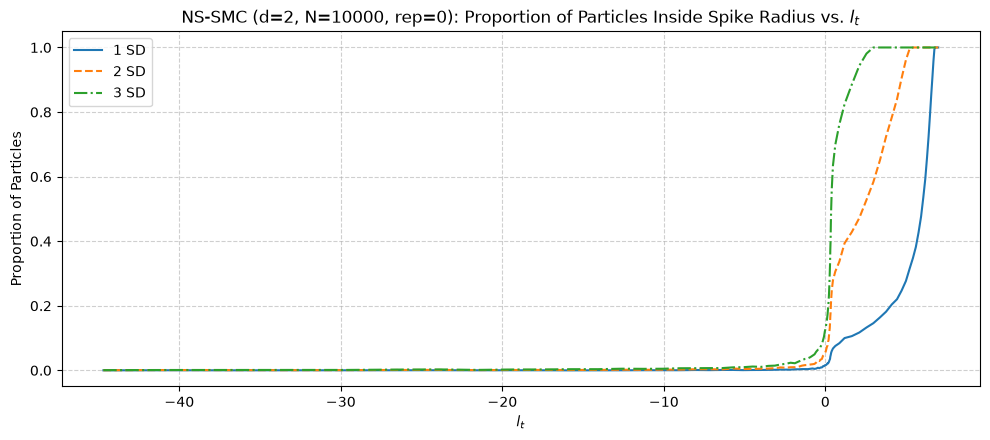

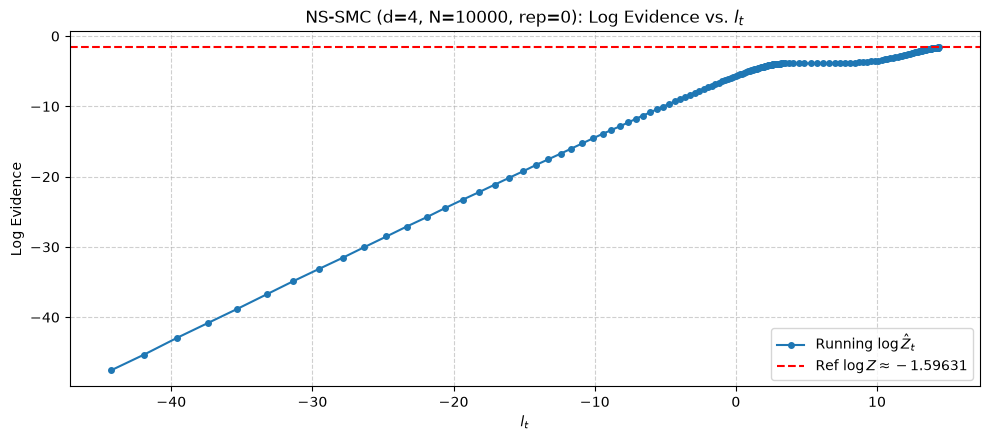

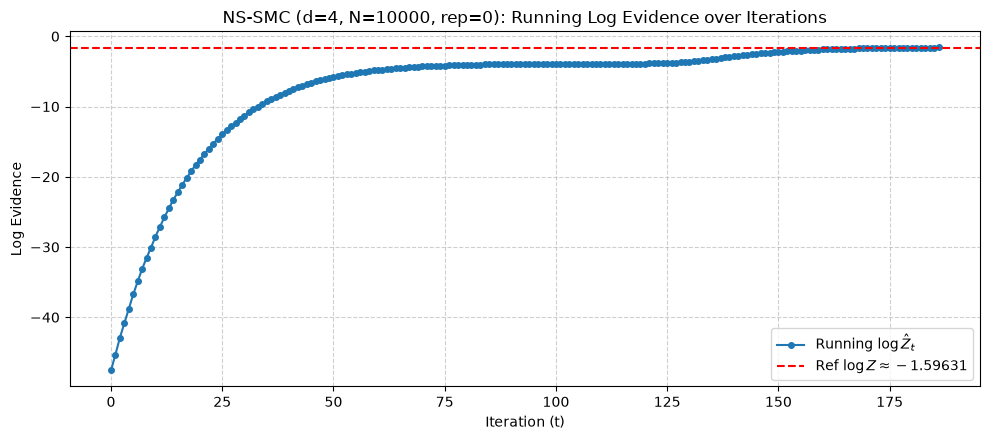

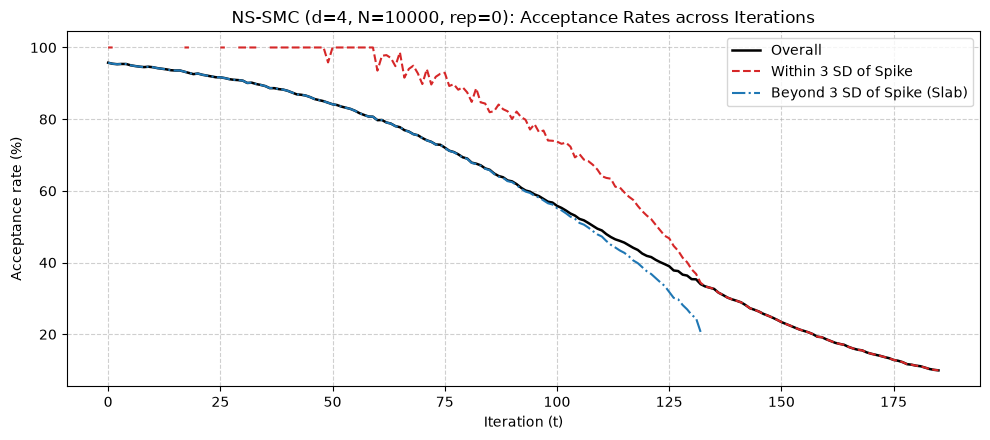

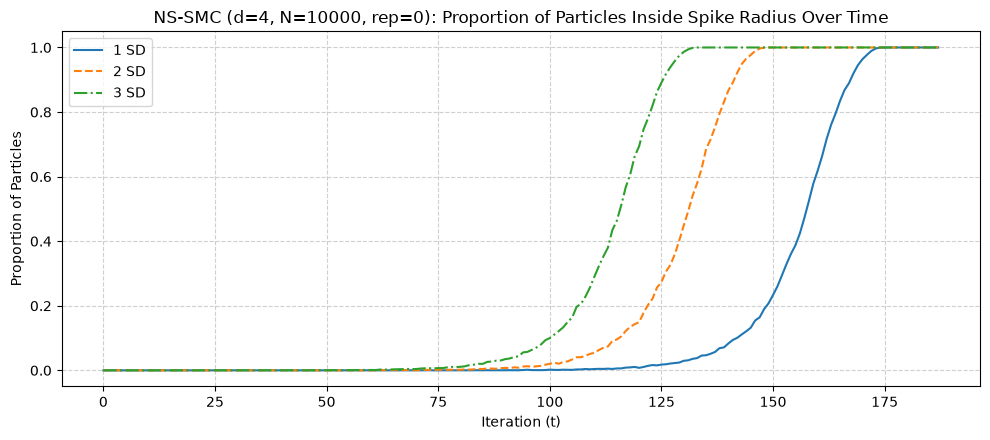

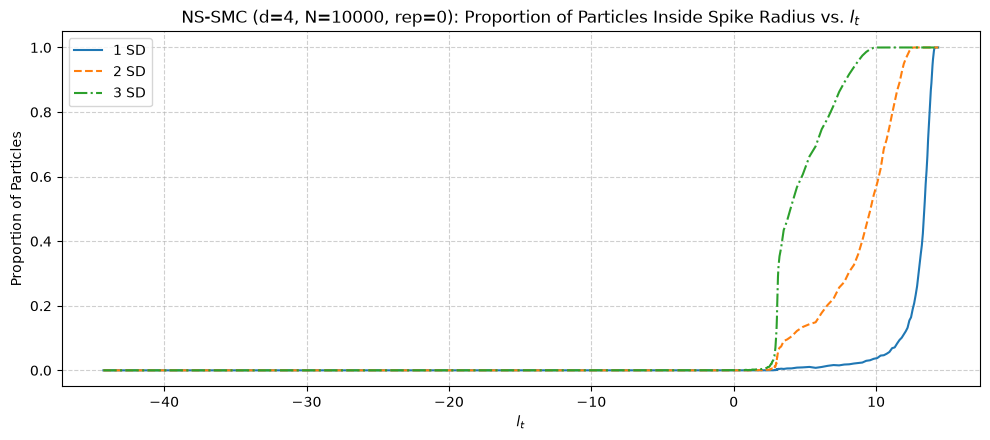

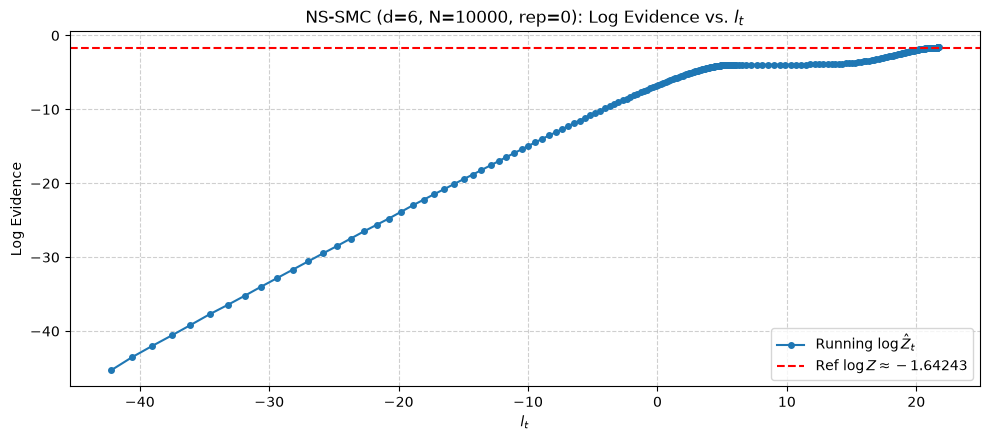

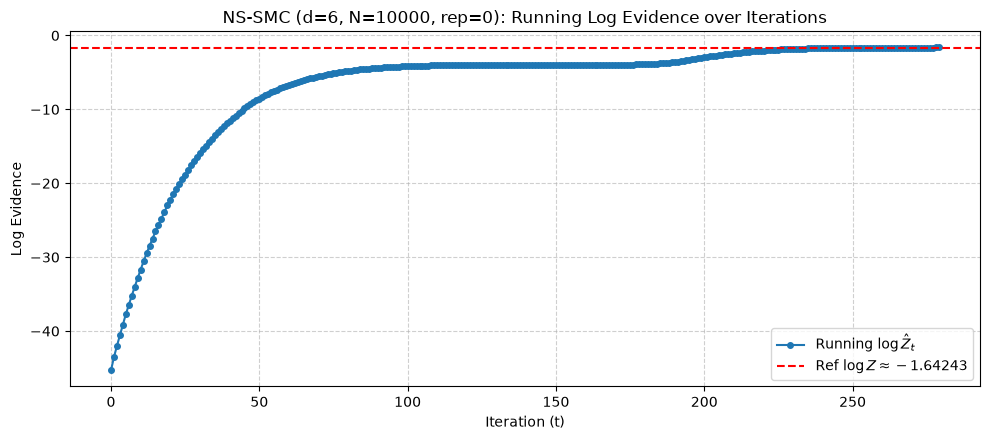

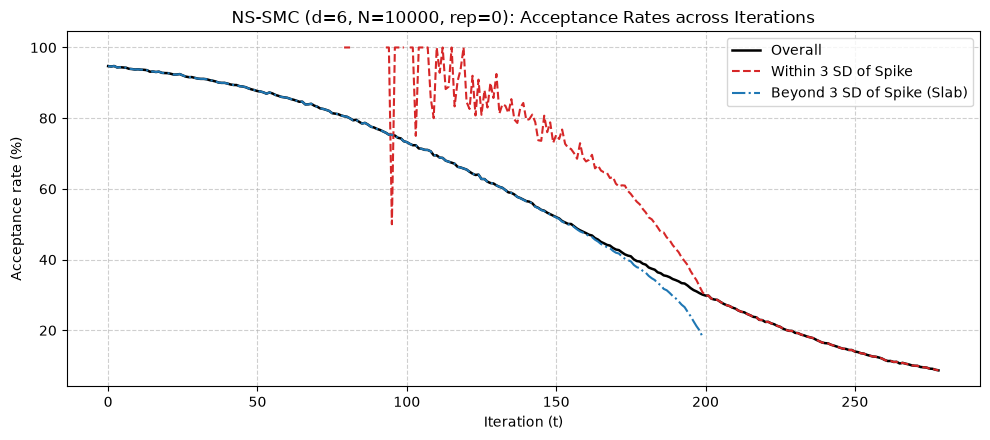

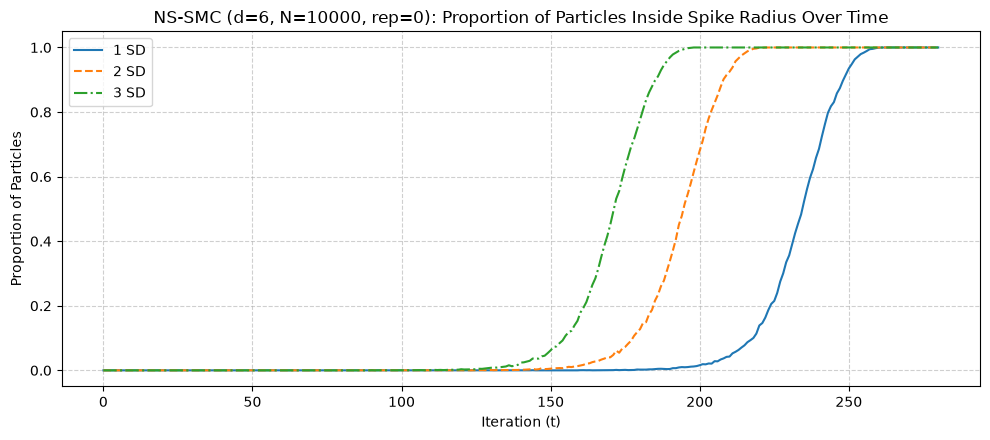

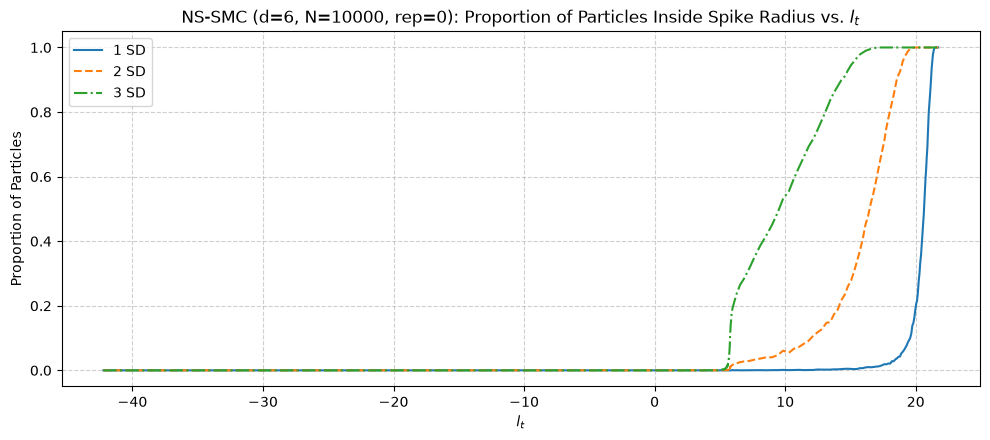

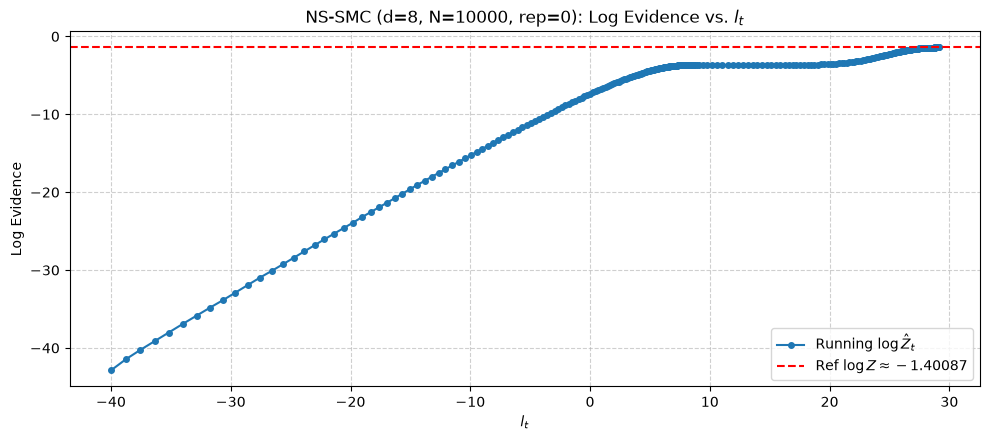

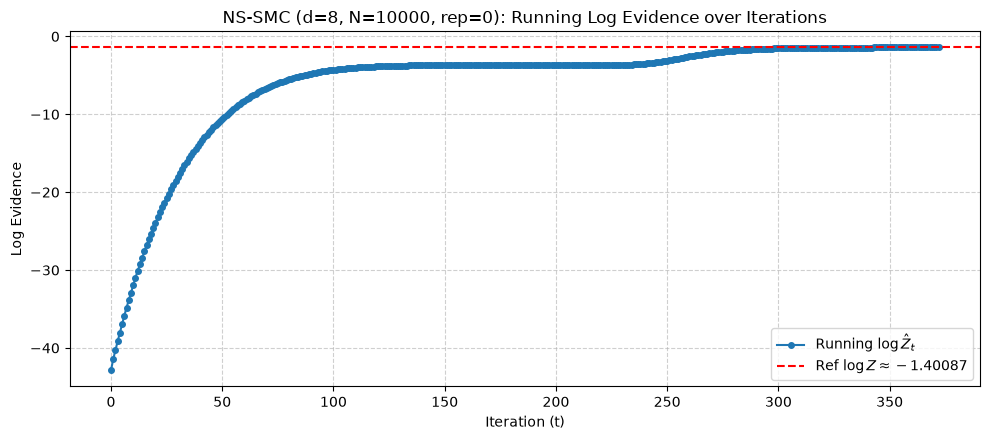

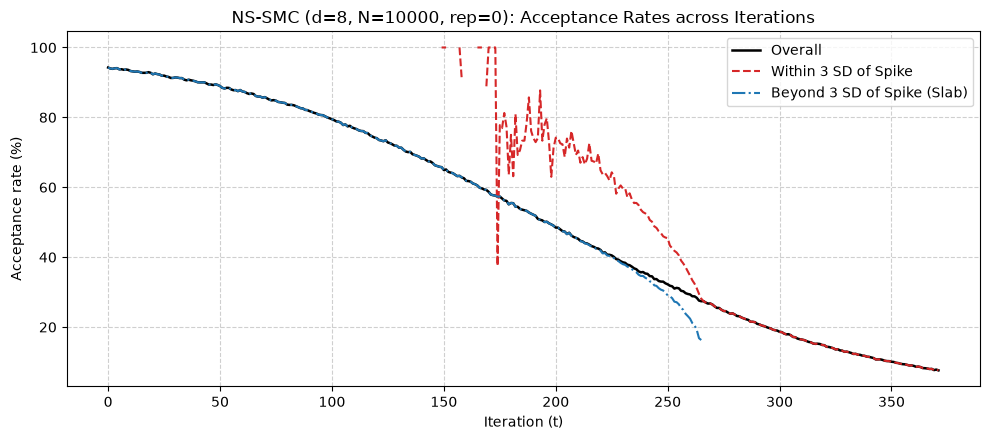

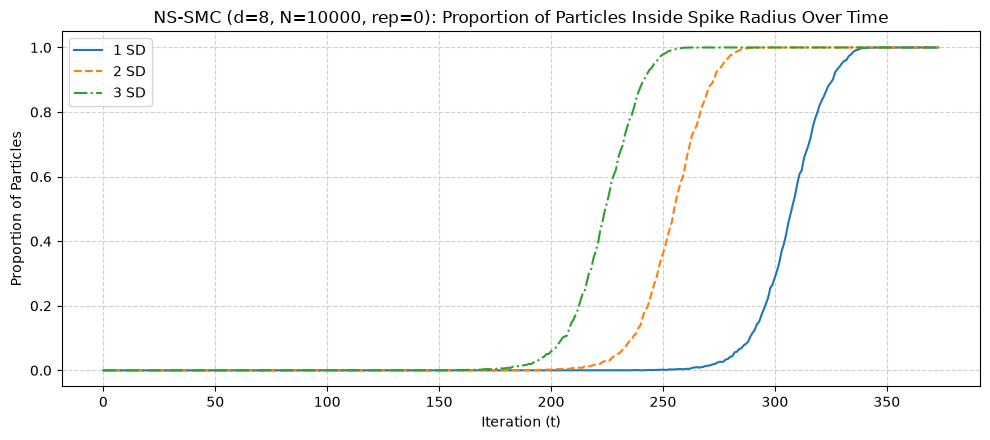

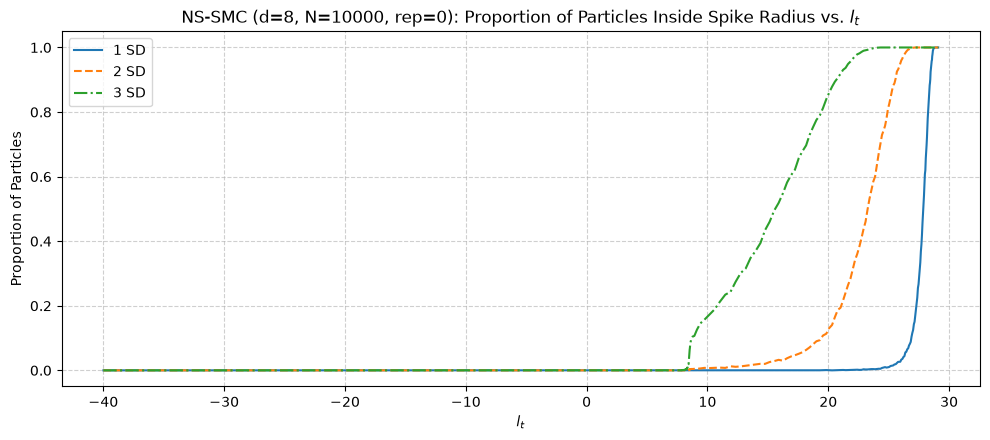

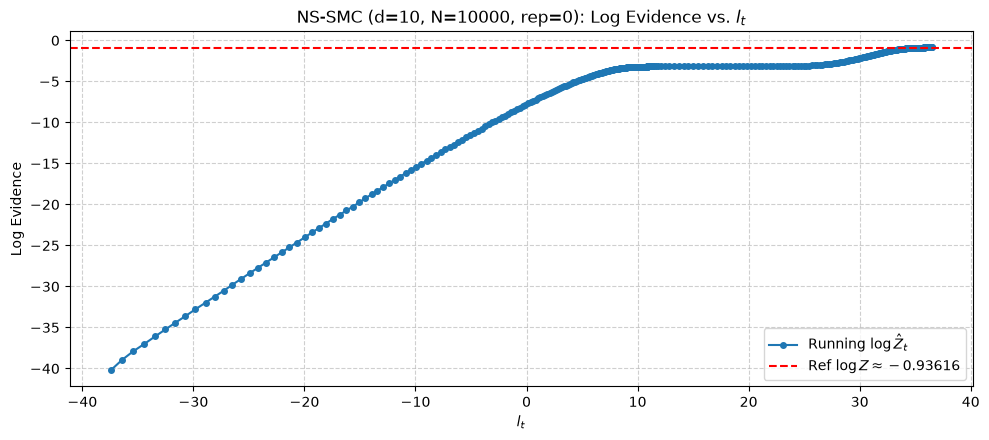

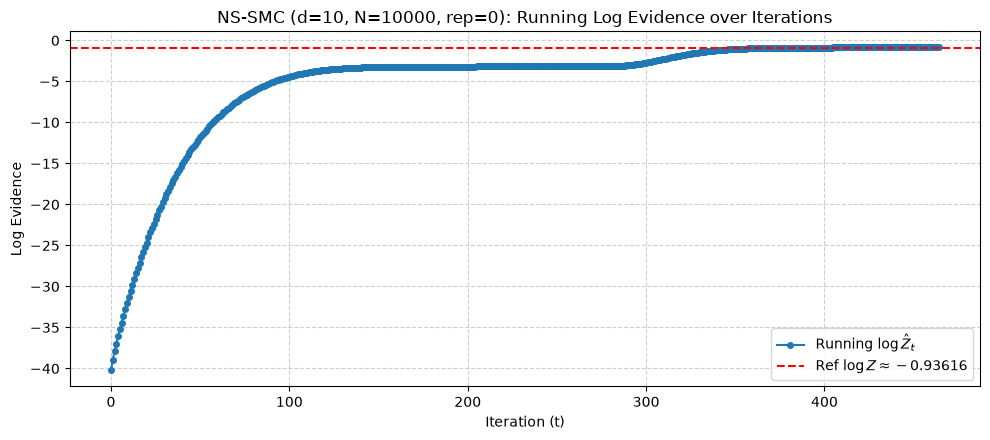

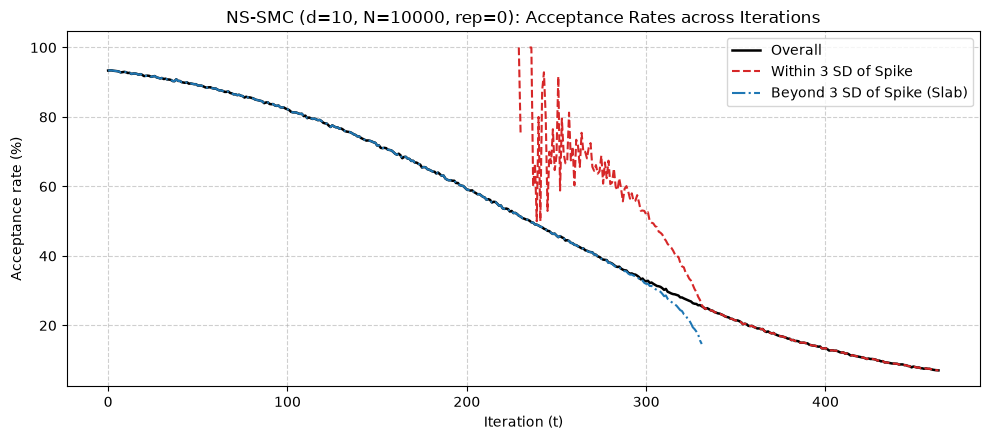

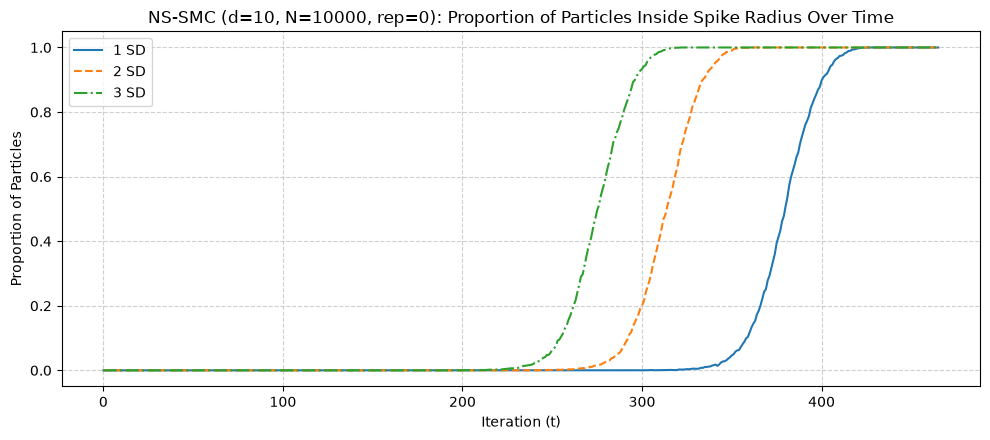

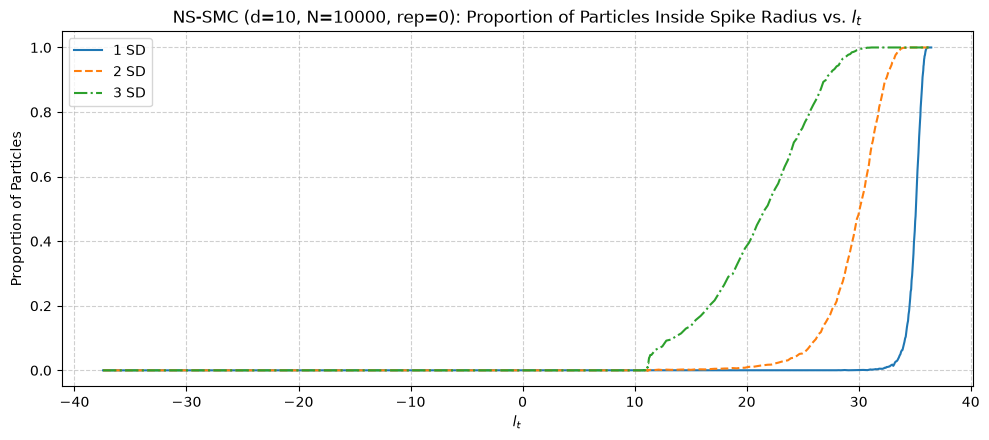

In [46]:
df_ns_smc_2 = pd.concat(
    [
        run_ns_smc_for_d(d_val, levels_ans_smc_2, ans_meta_by_run_2, num_repeats=num_repeats, plot_diagnostics=True)
        for d_val in dims
    ],
    ignore_index=True,
)

In [47]:
df_ns_smc_2["true_Z"] = df_ns_smc_2["d"].map(z_by_d)
df_ns_smc_2["true_log_Z"] = df_ns_smc_2["d"].map(log_z_by_d)
df_ns_smc_2["abs_error"] = np.sqrt((df_ns_smc_2["Z"] - df_ns_smc_2["true_Z"]) ** 2)
df_ns_smc_2[["d", "log_evidence", "true_log_Z", "Z", "true_Z", "abs_error", "total_prop_spike", "total_prop_slab"]]

,d,log_evidence,true_log_Z,Z,true_Z,abs_error,total_prop_spike,total_prop_slab
0,2,-1.151131,-1.144730,0.316279,0.318310,0.002031,100000,0
1,4,-1.591627,-1.596313,0.203594,0.202642,0.000952,100000,0
2,6,-1.626326,-1.642430,0.196651,0.193509,0.003142,100000,0
3,8,-1.419445,-1.400866,0.241848,0.246383,0.004535,100000,0
4,10,-0.864541,-0.936158,0.421245,0.392131,0.029114,100000,0
